# Mfasha: a Kinyarwanda agriculture assistant

A farmer asks a question in Kinyarwanda, by typing or by voice, and gets a short answer in Kinyarwanda, as text and as speech. The answer is taken from a collection of agriculture passages, and the assistant refuses when the passages do not contain the answer.

**How it works**

1. **Speech to text.** `facebook/mms-1b-all` with the Kinyarwanda adapter, fine-tuned on studio recordings (27.7% word errors on a held-out voice, 30.1% before fine-tuning).
2. **Retrieval.** BM25 combined with a fine-tuned `multilingual-e5-large` finds the right passage (R@1 0.87 on passages never seen in training, R@10 0.99).
3. **Answer.** `openai/gpt-oss-120b` on Groq copies the sentences that answer the question, word for word. Numbers that are not in the passages are blocked, and off-topic questions are refused.
4. **Text to speech.** `facebook/mms-tts-kin`. Numbers, units and percentages are first written out as Kinyarwanda words.

**Data**

- `C4IR-RW/kinya-ag-retrieval`: passages, questions and triplets for retrieval.
- `C4IR-RW/kinya-ag-tts`: studio recordings of four voices. Three voices are used for ASR training, and `rw_ag_tts_male2` is kept aside as the test voice.

**Results**

| Part | Measure | Result |
|---|---|---|
| Retrieval | R@1 on unseen passages (test) | 0.866 |
| Retrieval | R@10 on unseen passages (test) | 0.994 |
| Speech to text | Word error rate on a held-out voice | 27.7% (baseline 30.1%) |
| Answers | Share copied word for word (6 dev questions) | 94% |
| Answers | Off-topic questions refused | 3 of 3 |
| Voice | Round-trip word error rate, stock voice | 0.228 |
| Voice | Round-trip word error rate, fine-tuned voice | 0.695 |

**A finding worth knowing.** I fine-tuned the voice on 1.7 hours of one speaker, and it came out clearly worse than the stock voice when read back by the ASR (0.695 against 0.228). The stock voice is therefore used. The fine-tuning cells are kept so the experiment can be repeated.


In [1]:
# install what the whole notebook needs
!pip install -q transformers datasets accelerate peft sentence-transformers rank_bm25 jiwer librosa soundfile evaluate

import os, sys, random, platform
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch

# google drive holds the data, models and results so nothing is lost when the runtime resets
from google.colab import drive, userdata
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Mfasha chatbot")
DATA_DIR    = ROOT / "data"
MODELS_DIR  = ROOT / "models"
RESULTS_DIR = ROOT / "results"
AUDIO_DIR   = ROOT / "audio"

for folder in (DATA_DIR, MODELS_DIR, RESULTS_DIR, AUDIO_DIR):
    folder.mkdir(parents=True, exist_ok=True)


@dataclass(frozen=True)
class Config:
    seed: int = 42

    # datasets on the hugging face hub
    retrieval_repo: str = "C4IR-RW/kinya-ag-retrieval"
    tts_repo: str = "C4IR-RW/kinya-ag-tts"

    # retrieval
    base_embedder: str = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
    top_k: int = 5

    # answer generation
    llm_model: str = "openai/gpt-oss-120b"
    llm_temperature: float = 0.0

    # speech to text
    asr_model: str = "facebook/mms-1b-all"
    asr_lang: str = "kin"
    sample_rate: int = 16000


CFG = Config()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CFG.seed)

# keys come from the Colab secrets panel
def get_secret(name):
    try:
        return userdata.get(name)
    except Exception:
        return os.getenv(name)


HF_TOKEN = get_secret("HF_TOKEN")
GROQ_API_KEY = get_secret("GROQ_API_KEY")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("python  :", sys.version.split()[0], f"({platform.system()})")
print("torch   :", torch.__version__)
print("device  :", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")
print("root    :", ROOT)
print("hf token:", "found" if HF_TOKEN else "missing, add HF_TOKEN in Colab secrets")
print("groq key:", "found" if GROQ_API_KEY else "missing, add GROQ_API_KEY in Colab secrets")
if DEVICE == "cpu":
    print("no GPU, go to Runtime > Change runtime type and pick a GPU before training anything")

Mounted at /content/drive
python  : 3.13.16 (Linux)
torch   : 2.11.0+cu130
device  : cuda (Tesla T4)
root    : /content/drive/MyDrive/Mfasha chatbot
hf token: found
groq key: found


In [5]:
import re
import csv
import pandas as pd
from huggingface_hub import hf_hub_download

CLEAN_DIR = DATA_DIR / "clean"
CLEAN_DIR.mkdir(exist_ok=True)


def fetch(name):
    return hf_hub_download(CFG.retrieval_repo, name, repo_type="dataset")


def read_lines(name, keep_blank=False):
    with open(fetch(name), encoding="utf-8") as f:
        lines = [l.strip().strip('"') for l in f]
    return lines if keep_blank else [l for l in lines if l]


# the raw text has spaces before punctuation and after apostrophes
# this puts the text back the way it is normally written, so the LLM and the voice later get clean input
def clean_text(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"(?<=\w)'\s+(?=\w)", "'", t)
    t = re.sub(r"(\.\s*){2,}", "... ", t)
    t = re.sub(r"\s+([,.;:!?)\]])", r"\1", t)
    t = re.sub(r"([(\[])\s+", r"\1", t)
    t = re.sub(r"\s+", " ", t)
    return t.strip()


def heading_only(t):
    if ":" not in t:
        return len(re.findall(r"\w", t)) < 10
    body = t.split(":", 1)[1]
    return len(re.findall(r"\w", body)) == 0


passage_ids = read_lines("rw_ag_retrieval_passage_id.txt")
passage_raw = read_lines("rw_ag_retrieval_passage_text.txt")
assert len(passage_ids) == len(passage_raw), "passage ids and texts do not line up"

# blank lines are kept for queries so the ids and texts stay matched line by line
query_ids = read_lines("rw_ag_retrieval_query_id.txt", keep_blank=True)
query_raw = read_lines("rw_ag_retrieval_query_text.txt", keep_blank=True)
assert len(query_ids) == len(query_raw), "query ids and texts do not line up"

passages = pd.DataFrame({"pid": passage_ids, "text": [clean_text(t) for t in passage_raw]})
passages["empty"] = passages["text"].map(heading_only)

queries = pd.DataFrame({"qid": query_ids, "text": [clean_text(t) for t in query_raw]})
queries = queries[queries["qid"] != ""].reset_index(drop=True)

bad_pids = set(passages.loc[passages["empty"], "pid"])
good = passages[~passages["empty"]].reset_index(drop=True)
print(f"passages: {len(passages)} total, {len(bad_pids)} heading-only dropped, {len(good)} kept")

qid2text = dict(zip(queries["qid"], queries["text"]))
pid2text = dict(zip(good["pid"], good["text"]))


def load_split(split):
    df = pd.read_csv(
        fetch(f"rw_ag_retrieval_qpntriplets_{split}.tsv"),
        sep="\t", header=None, names=["qid", "pos_pid", "neg_pid"],
        quoting=csv.QUOTE_NONE, dtype=str,
    )
    raw = len(df)
    # keep only rows whose question and positive passage still exist after cleaning
    df = df[df["qid"].isin(qid2text) & df["pos_pid"].isin(pid2text)]
    df = df[df["neg_pid"].isin(pid2text)].reset_index(drop=True)
    pairs = df[["qid", "pos_pid"]].drop_duplicates().reset_index(drop=True)
    return df, pairs, raw


triplets, pairs, raw_rows = {}, {}, {}
for s in ("train", "dev", "test"):
    triplets[s], pairs[s], raw_rows[s] = load_split(s)

summary = pd.DataFrame({
    s: {
        "raw triplet rows": raw_rows[s],
        "usable triplet rows": len(triplets[s]),
        "questions": pairs[s]["qid"].nunique(),
        "distinct passages": pairs[s]["pos_pid"].nunique(),
    } for s in triplets
})
print(summary.to_string(), "\n")

# no question or passage should leak from train into dev or test
q_sets = {s: set(pairs[s]["qid"]) for s in pairs}
p_sets = {s: set(pairs[s]["pos_pid"]) for s in pairs}
print("shared questions  train/dev:", len(q_sets["train"] & q_sets["dev"]), "| train/test:", len(q_sets["train"] & q_sets["test"]))
print(f"test passages also in train: {len(p_sets['test'] & p_sets['train'])} of {len(p_sets['test'])}")
print(f"dev passages also in train : {len(p_sets['dev'] & p_sets['train'])} of {len(p_sets['dev'])}\n")

# look at a few before and after to make sure the cleaning did what we wanted
for i in (0, 1, 2):
    print("before:", passage_raw[i][:160])
    print("after :", passages.loc[i, "text"][:160], "\n")

# save the clean copies in a new folder, ids only for the triplets to keep the files small
good.to_json(CLEAN_DIR / "passages.jsonl", orient="records", lines=True, force_ascii=False)
queries.to_json(CLEAN_DIR / "queries.jsonl", orient="records", lines=True, force_ascii=False)
for s in triplets:
    triplets[s].to_csv(CLEAN_DIR / f"triplets_{s}.csv", index=False)
    pairs[s].to_csv(CLEAN_DIR / f"pairs_{s}.csv", index=False)
print("saved to", CLEAN_DIR)

rw_ag_retrieval_passage_id.txt:   0%|          | 0.00/8.88k [00:00<?, ?B/s]

rw_ag_retrieval_passage_text.txt:   0%|          | 0.00/577k [00:00<?, ?B/s]

rw_ag_retrieval_query_id.txt:   0%|          | 0.00/215k [00:00<?, ?B/s]

rw_ag_retrieval_query_text.txt:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

passages: 984 total, 43 heading-only dropped, 941 kept


rw_ag_retrieval_qpntriplets_train.tsv: reconstructing file:   0%|          |  0.00B / 55.2MB            

rw_ag_retrieval_qpntriplets_train.tsv: downloading bytes:           |  0.00B            

rw_ag_retrieval_qpntriplets_dev.tsv:   0%|          | 0.00/569k [00:00<?, ?B/s]

rw_ag_retrieval_qpntriplets_test.tsv:   0%|          | 0.00/955k [00:00<?, ?B/s]

                       train    dev   test
raw triplet rows     1901200  19600  32900
usable triplet rows  1731732  18551  31193
questions              18123    196    329
distinct passages        900     10     20 

shared questions  train/dev: 0 | train/test: 0
test passages also in train: 0 of 20
dev passages also in train : 0 of 10

before: Inkoko irwaye irangwa n' ibi bikurikira : Iyo indwara yateye mu nkoko , ibigaragaza ubuzima bwazo bwiza birabura cyangwa bigahinduka . Usanga inkoko zigunze , z
after : Inkoko irwaye irangwa n'ibi bikurikira: Iyo indwara yateye mu nkoko, ibigaragaza ubuzima bwazo bwiza birabura cyangwa bigahinduka. Usanga inkoko zigunze, zikonj 

before: Uburyo indwara y' ubushita yandura mu nkoko : Ino ndwara iboneka mu nkoko zose ( into n' inkuru ) . Ni indwara mbi cyane iterwa na virusi . Inkoko zirwaye zandu
after : Uburyo indwara y'ubushita yandura mu nkoko: Ino ndwara iboneka mu nkoko zose (into n'inkuru). Ni indwara mbi cyane iterwa na virusi. Inkoko zirw

In [6]:
rng = np.random.default_rng(CFG.seed)
train_pairs = pairs["train"]

# take 50 whole passages out of train and add them to the original dev passages
train_pids = np.array(sorted(train_pairs["pos_pid"].unique()))
rng.shuffle(train_pids)
extra_dev_pids = set(train_pids[:50])
in_extra = train_pairs["pos_pid"].isin(extra_dev_pids)

dev_unseen  = pd.concat([pairs["dev"], train_pairs[in_extra]]).reset_index(drop=True)
test_unseen = pairs["test"].reset_index(drop=True)

# for the passages that stay in training, hold out a few questions each
# these passages are in the search index at test time, like the real chatbot
rest = train_pairs[~in_extra].sample(frac=1, random_state=CFG.seed)
pos_in_passage = rest.groupby("pos_pid").cumcount()
passage_size   = rest.groupby("pos_pid")["qid"].transform("size")
enough = passage_size >= 8                     # skip passages with too few questions

dev_seen  = rest[enough & (pos_in_passage < 2)]
test_seen = rest[enough & (pos_in_passage >= 2) & (pos_in_passage < 4)]
train_final = rest.drop(dev_seen.index).drop(test_seen.index)

splits = {
    "train": train_final,
    "dev_seen": dev_seen,
    "test_seen": test_seen,
    "dev_unseen": dev_unseen,
    "test_unseen": test_unseen,
}

# a question must live in exactly one split
all_qids = [set(df_s["qid"]) for df_s in splits.values()]
assert sum(len(s) for s in all_qids) == len(set().union(*all_qids)), "a question is in two splits"

# an unseen split must not share passages with training
for name in ("dev_unseen", "test_unseen"):
    assert not (set(splits[name]["pos_pid"]) & set(train_final["pos_pid"])), f"{name} leaks into train"

report = pd.DataFrame({
    name: {"questions": len(df_s), "passages": df_s["pos_pid"].nunique()}
    for name, df_s in splits.items()
}).T
print(report.to_string())

SPLIT_DIR = CLEAN_DIR / "splits"
SPLIT_DIR.mkdir(exist_ok=True)
for name, df_s in splits.items():
    df_s.reset_index(drop=True).to_csv(SPLIT_DIR / f"{name}.csv", index=False)
print("saved to", SPLIT_DIR)

             questions  passages
train            14232       850
dev_seen          1394       697
test_seen         1394       697
dev_unseen        1299        60
test_unseen        329        20
saved to /content/drive/MyDrive/Mfasha chatbot/data/clean/splits


In [7]:
import re, gc
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

EMB_DIR = RESULTS_DIR / "emb"
EMB_DIR.mkdir(exist_ok=True)

# True scores every baseline again. needed once after the float32 fix, then set it back to False
REDO_BASELINES = True

passage_pids  = good["pid"].tolist()
passage_texts = good["text"].tolist()
pid2idx = {p: i for i, p in enumerate(passage_pids)}

# one table with every evaluation question, so each model only has to encode them once
eval_names = ["dev_seen", "test_seen", "dev_unseen", "test_unseen"]
ev = pd.concat([splits[n].assign(split=n) for n in eval_names]).reset_index(drop=True)
ev["question"] = ev["qid"].map(qid2text)
questions = ev["question"].tolist()
gold = ev["pos_pid"].map(pid2idx).to_numpy()
print(f"{len(questions)} eval questions, searching {len(passage_texts)} passages")


def tok(text):
    return re.findall(r"\w+", text.lower())


def to_rank(S):
    return np.argsort(np.argsort(-S, axis=1), axis=1) + 1


def rrf(mats, weights, k=60):
    return sum(w / (k + to_rank(S)) for S, w in zip(mats, weights))


def score(S, name):
    S = np.asarray(S, dtype=np.float32)
    g = S[np.arange(len(S)), gold][:, None]
    rank = (S >= g).sum(axis=1)          # ties count against the system
    rows = []
    for split in eval_names:
        m = (ev["split"] == split).to_numpy()
        r = rank[m]
        rows.append({
            "system": name, "split": split,
            "R@1": (r <= 1).mean(), "R@5": (r <= 5).mean(), "R@10": (r <= 10).mean(),
            "MRR@10": np.where(r <= 10, 1 / r, 0).mean(),
        })
    return rows


bm25 = BM25Okapi([tok(t) for t in passage_texts])
S_bm25 = np.vstack([bm25.get_scores(tok(q)) for q in questions])
rows = score(S_bm25, "BM25")

# name: (hub id, query prefix, passage prefix, max length)
embedders = {
    "mpnet (current)":  ("sentence-transformers/paraphrase-multilingual-mpnet-base-v2", "", "", 256),
    "multilingual-e5":  ("intfloat/multilingual-e5-large", "query: ", "passage: ", 512),
    "bge-m3":           ("BAAI/bge-m3", "", "", 512),
    "labse":            ("sentence-transformers/LaBSE", "", "", 256),
}

baseline_csv = RESULTS_DIR / "retrieval_baselines.csv"
if baseline_csv.exists() and not REDO_BASELINES:
    results = pd.read_csv(baseline_csv)
else:
    for name, (hub_id, q_pre, p_pre, max_len) in embedders.items():
        model = SentenceTransformer(hub_id, device=DEVICE, model_kwargs={"torch_dtype": torch.float16})
        model.max_seq_length = max_len

        cache = EMB_DIR / (hub_id.replace("/", "_") + "_passages.npy")
        if cache.exists():
            P = np.load(cache).astype(np.float32)
        else:
            P = model.encode([p_pre + t for t in passage_texts], batch_size=16,
                             normalize_embeddings=True, show_progress_bar=True).astype(np.float32)
            np.save(cache, P)

        Q = model.encode([q_pre + q for q in questions], batch_size=64,
                         normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
        S = Q @ P.T

        rows += score(S, name)
        rows += score(rrf([S_bm25, S], [1.0, 0.5]), f"BM25 + {name}")
        del model
        gc.collect()
        torch.cuda.empty_cache()

    results = pd.DataFrame(rows)
    results.to_csv(baseline_csv, index=False)

for metric in ("R@1", "R@10", "MRR@10"):
    print(f"\n{metric}")
    print(results.pivot(index="system", columns="split", values=metric)[eval_names].round(3).to_string())

4416 eval questions, searching 941 passages


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/114 [00:00<?, ?B/s]

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 2.36MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            


R@1
split                   dev_seen  test_seen  dev_unseen  test_unseen
system                                                              
BM25                       0.488      0.487       0.488        0.489
BM25 + bge-m3              0.501      0.493       0.460        0.541
BM25 + labse               0.306      0.290       0.303        0.301
BM25 + mpnet (current)     0.172      0.183       0.196        0.204
BM25 + multilingual-e5     0.524      0.517       0.509        0.468
bge-m3                     0.357      0.348       0.321        0.328
labse                      0.080      0.082       0.082        0.085
mpnet (current)            0.031      0.032       0.031        0.046
multilingual-e5            0.383      0.400       0.393        0.316

R@10
split                   dev_seen  test_seen  dev_unseen  test_unseen
system                                                              
BM25                       0.816      0.814       0.811        0.796
BM25 + bge-m3          

In [ ]:
from datasets import Dataset
from transformers import TrainerCallback
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers

BASE_ID = "intfloat/multilingual-e5-large"
OUT_DIR = MODELS_DIR / "kinya-e5-large"
BEST_DIR = OUT_DIR / "best"
Q_PRE, P_PRE = "query: ", "passage: "
EPOCHS = 3
PATIENCE = 2
# the saved retriever was trained with the old hard negatives. set True once to retrain with the fixed ones
RETRAIN = False
need_training = RETRAIN or not (BEST_DIR / "config.json").exists()


if need_training:
    train_df = splits["train"].reset_index(drop=True)
    train_q = train_df["qid"].map(qid2text).tolist()
    pos_idx = train_df["pos_pid"].map(pid2idx).to_numpy()
    rng = np.random.default_rng(CFG.seed)

    # bm25 negatives, only from passages that appear as training positives
    train_cols = np.zeros(len(passage_texts), bool)
    train_cols[np.unique(pos_idx)] = True

    S_train = np.vstack([bm25.get_scores(tok(q)) for q in train_q])
    S_train[:, ~train_cols] = -np.inf
    order = np.argsort(-S_train, axis=1)[:, :40]
    hard_idx = []
    for row, p in zip(order, pos_idx):
        wrong = [j for j in row if j != p]
        hard_idx.append(rng.choice(wrong[1:15]))
    del S_train

    train_ds = Dataset.from_dict({
        "anchor":   [Q_PRE + q for q in train_q],
        "positive": [P_PRE + passage_texts[i] for i in pos_idx],
        "negative": [P_PRE + passage_texts[i] for i in hard_idx],
    })

    model = SentenceTransformer(BASE_ID, device=DEVICE)
    model.max_seq_length = 256

    # the 250k word table is half the model and too big for a T4 to train
    model[0].auto_model.embeddings.word_embeddings.weight.requires_grad = False
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_all = sum(p.numel() for p in model.parameters())
    print(f"training {n_train / 1e6:.0f}M of {n_all / 1e6:.0f}M parameters")

    dev_mask = ev["split"].isin(["dev_seen", "dev_unseen"]).to_numpy()
    dev_queries = [Q_PRE + q for q, use_q in zip(questions, dev_mask) if use_q]
    dev_gold = gold[dev_mask]
    dev_split = ev["split"].to_numpy()[dev_mask]


    def dev_scores(m):
        with torch.autocast("cuda", dtype=torch.float16):
            P = m.encode([P_PRE + t for t in passage_texts], batch_size=32, normalize_embeddings=True)
            Q = m.encode(dev_queries, batch_size=64, normalize_embeddings=True)
        S = Q.astype(np.float32) @ P.astype(np.float32).T
        g = S[np.arange(len(S)), dev_gold][:, None]
        rank = (S >= g).sum(axis=1)
        out = {}
        for sp in ("dev_seen", "dev_unseen"):
            r = rank[dev_split == sp]
            out[f"{sp} R@1"] = (r <= 1).mean()
            out[f"{sp} R@10"] = (r <= 10).mean()
        return out


    history = []
    best = {"score": -1.0, "epoch": None, "bad_epochs": 0}


    class EpochCheck(TrainerCallback):
        def on_epoch_end(self, args, state, control, **kwargs):
            epoch = int(round(state.epoch))
            sc = dev_scores(model)
            history.append({"epoch": epoch, **sc})
            now = (sc["dev_seen R@1"] + sc["dev_unseen R@1"]) / 2
            print(f"\nepoch {epoch}: " + " | ".join(f"{k} {v:.3f}" for k, v in sc.items()))
            if now > best["score"]:
                best.update(score=now, epoch=epoch, bad_epochs=0)
                model.save_pretrained(str(BEST_DIR))
                print("new best, saved")
            else:
                best["bad_epochs"] += 1
                if best["bad_epochs"] >= PATIENCE:
                    print("no gain for 2 epochs, stopping")
                    control.should_training_stop = True


    # scale 20 gave good dev scores, so it stays
    loss = losses.CachedMultipleNegativesRankingLoss(model, mini_batch_size=2, scale=20)

    args = SentenceTransformerTrainingArguments(
        output_dir=str(OUT_DIR / "tmp"),
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=64,
        learning_rate=2e-5,
        warmup_ratio=0.1,               # newer transformers warns about this name, it still works
        weight_decay=0.01,
        fp16=True,
        batch_sampler=BatchSamplers.NO_DUPLICATES,
        save_strategy="no",
        logging_steps=50,
        report_to="none",
        seed=CFG.seed,
    )

    trainer = SentenceTransformerTrainer(
        model=model, args=args, train_dataset=train_ds, loss=loss, callbacks=[EpochCheck()]
    )
    trainer.train()

    # the real loss values, saved so the plots never need typed-in numbers
    log = [x for x in trainer.state.log_history if "loss" in x]
    pd.DataFrame({"step": [x["step"] for x in log], "loss": [x["loss"] for x in log]}).to_csv(
        RESULTS_DIR / "retrieval_loss_log.csv", index=False)

    hist = pd.DataFrame(history).set_index("epoch")
    hist.to_csv(RESULTS_DIR / "retrieval_epoch_history.csv")
    print("\ndev score per epoch")
    print(hist.round(3).to_string())
    print("best epoch:", best["epoch"])

    del model, trainer
    gc.collect()
    torch.cuda.empty_cache()
else:
    # the model is already on drive, only the epoch table is needed for the plots
    hist = pd.read_csv(RESULTS_DIR / "retrieval_epoch_history.csv").set_index("epoch")
    print("saved retriever found, skipping training")
    print(hist.round(3).to_string())

# from here it runs in both cases: load the best model and score it
model = SentenceTransformer(str(BEST_DIR), device=DEVICE, model_kwargs={"torch_dtype": torch.float16})
model.max_seq_length = 256

P = model.encode([P_PRE + t for t in passage_texts], batch_size=16, normalize_embeddings=True).astype(np.float32)
Q = model.encode([Q_PRE + q for q in questions], batch_size=64, normalize_embeddings=True).astype(np.float32)
S_ft = Q @ P.T

new_rows = score(S_ft, "e5 fine-tuned")
for w in (0.5, 1.0, 2.0):
    new_rows += score(rrf([S_bm25, S_ft], [1.0, w]), f"BM25 + e5 fine-tuned (w={w})")

keep_systems = ["BM25", "multilingual-e5", "BM25 + multilingual-e5"]
compare = pd.concat([results[results["system"].isin(keep_systems)], pd.DataFrame(new_rows)])
compare = compare[compare["split"].isin(["dev_seen", "dev_unseen"])]
compare.to_csv(RESULTS_DIR / "retrieval_finetuned_dev.csv", index=False)

for metric in ("R@1", "R@10", "MRR@10"):
    print(f"\n{metric}")
    print(compare.pivot(index="system", columns="split", values=metric).round(3).to_string())

/tmp/ipykernel_9486/664770835.py:3: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
/tmp/ipykernel_9486/664770835.py:4: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

training 304M of 560M parameters


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,2.007597
100,0.288593
150,0.221661
200,0.181418
250,0.130149
300,0.103582
350,0.113236
400,0.096194
450,0.097439
500,0.062365


...

new best, saved

epoch 2: dev_seen R@1 0.912 | dev_seen R@10 0.994 | dev_unseen R@1 0.846 | dev_unseen R@10 0.981


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

new best, saved

epoch 3: dev_seen R@1 0.912 | dev_seen R@10 0.994 | dev_unseen R@1 0.844 | dev_unseen R@10 0.978

dev score per epoch
       dev_seen R@1  dev_seen R@10  dev_unseen R@1  dev_unseen R@10
epoch                                                              
1             0.886          0.990           0.846            0.975
2             0.912          0.994           0.846            0.981
3             0.912          0.994           0.844            0.978
best epoch: 2


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


R@1
split                         dev_seen  dev_unseen
system                                            
BM25                             0.488       0.488
BM25 + e5 fine-tuned (w=0.5)     0.614       0.619
BM25 + e5 fine-tuned (w=1.0)     0.676       0.661
BM25 + e5 fine-tuned (w=2.0)     0.758       0.737
BM25 + multilingual-e5           0.524       0.509
e5 fine-tuned                    0.912       0.847
multilingual-e5                  0.383       0.393

R@10
split                         dev_seen  dev_unseen
system                                            
BM25                             0.816       0.811
BM25 + e5 fine-tuned (w=0.5)     0.885       0.880
BM25 + e5 fine-tuned (w=1.0)     0.920       0.915
BM25 + e5 fine-tuned (w=2.0)     0.968       0.956
BM25 + multilingual-e5           0.849       0.836
e5 fine-tuned                    0.994       0.980
multilingual-e5                  0.706       0.684

MRR@10
split                         dev_seen  dev_unseen
system      

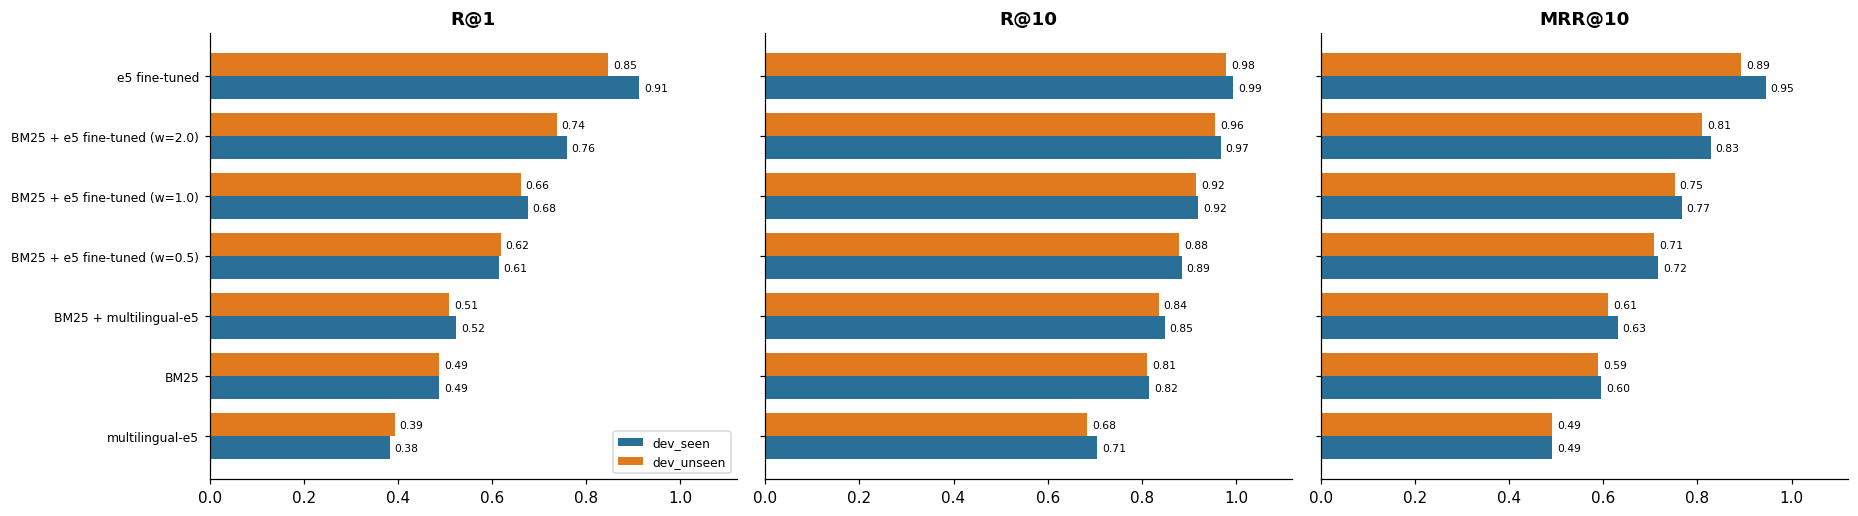

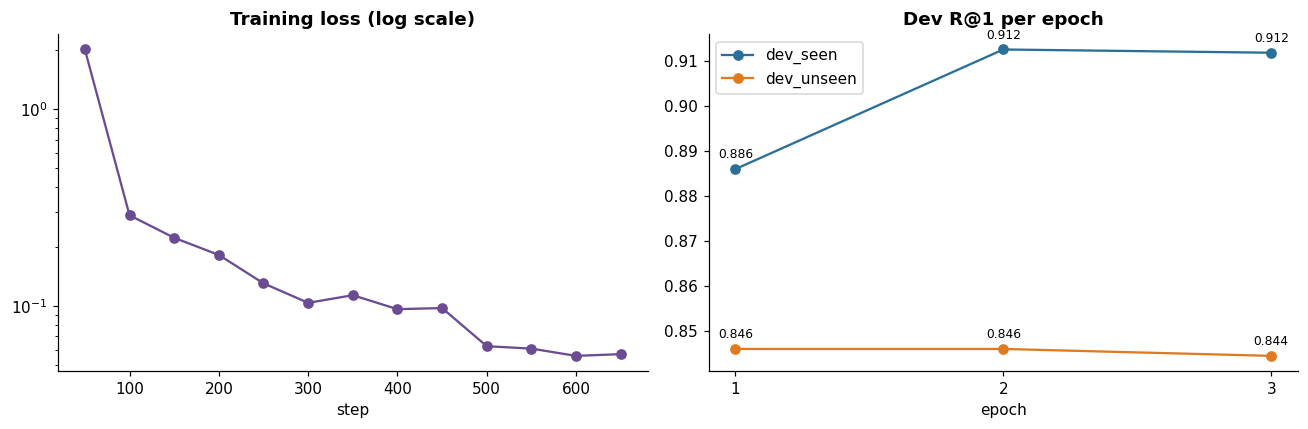

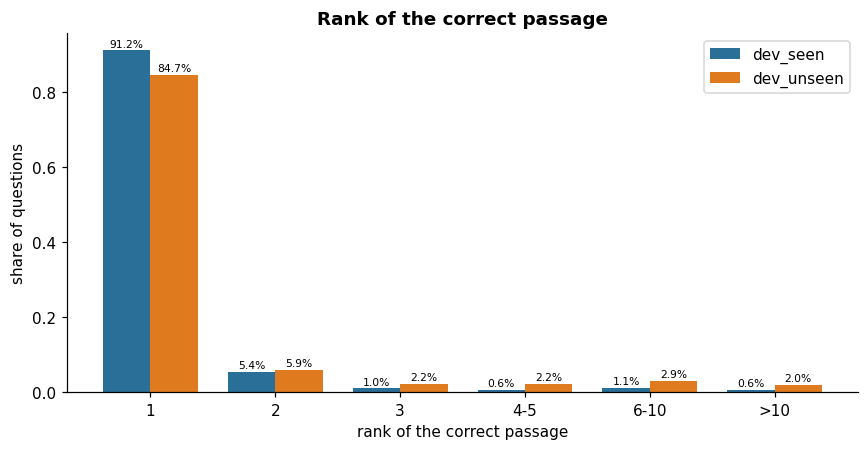

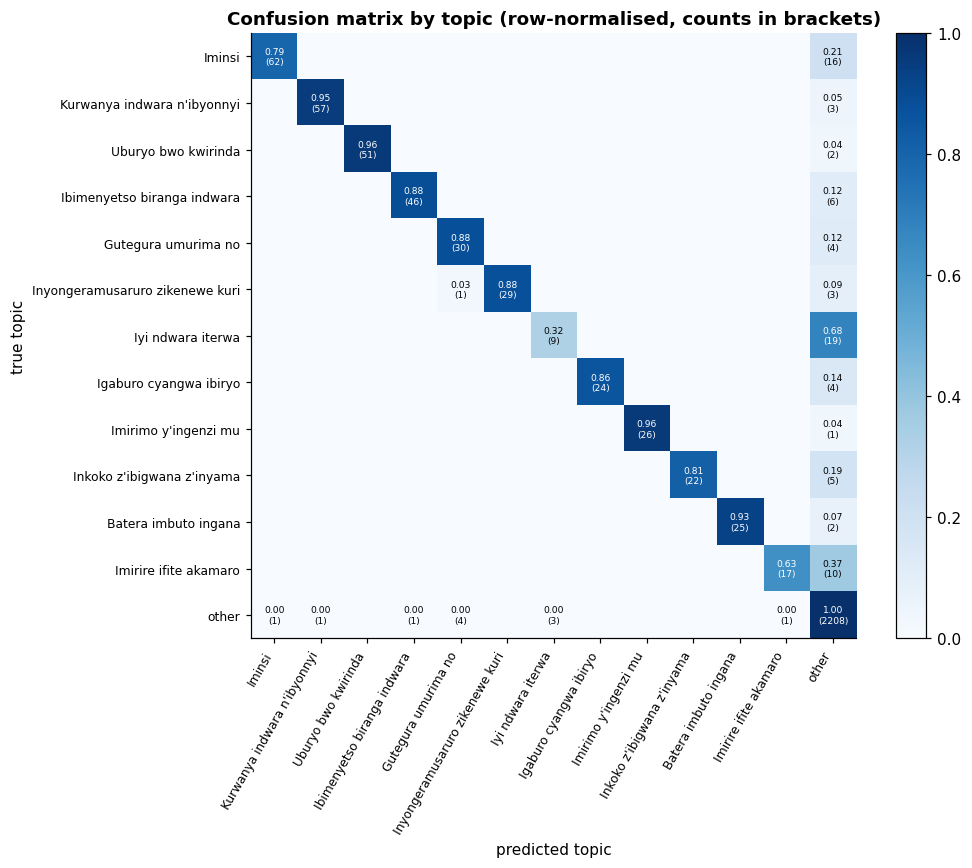

MOST CONFUSED PASSAGE PAIRS (true -> predicted)
 errors true_pid predicted_pid                                                              true_text                                                         predicted_text
     14 A248T675      A245T672 Gukata amashami y'ibiti mu myaka yambere ikurikira iterwa ry'ibiti ni  Iyo ibinyamacunga bimaze guterwa ni ngombwa kubifata neza ubibagarira,
     13 A754T582      A795T581 Iminsi: 0; Indwara ikingirwa: Marek; Inkingo: CEVAC MD HVT RISPENS; Uk Gahunda yo gukingira ku nkoko z'amagi: Ku munsi wa 0, urukingo rwa Mar
      8 A041T027      A030T004 Ubwishingizi butangwa n'ibigo by'ubwishingizi bibititiye ububasha byat Umuhinzi ukeneye ubwishingizi bw'ibihingwa, agana ibigo bitanga ubwish
      8 A255T686      A252T683 Iyi ndwara iterwa na bagiteri, yangiza cyane amako menshi y'ibinyamacu Iyi ndwara y'umuhondo w'amababi y'Amacunga, Mandarine n'indimu ni imwe
      7 A014T618      A746T564 Umubare w'inkoko n'ubuso zakororerwaho, hagendewe kumins

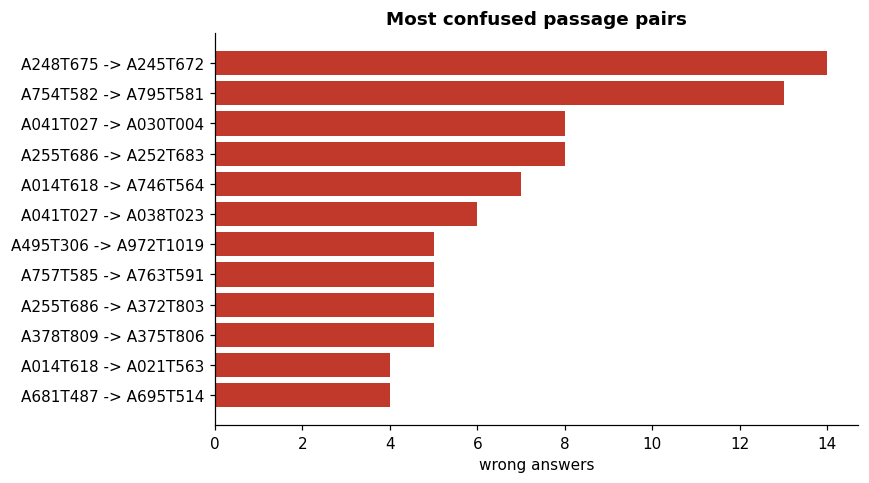


WEAKEST PASSAGES (at least 3 dev questions)
     pid  n   r1                                                                             text
A248T675 25 0.12 Gukata amashami y'ibiti mu myaka yambere ikurikira iterwa ry'ibiti ni ngombwa ku
A255T686 26 0.27 Iyi ndwara iterwa na bagiteri, yangiza cyane amako menshi y'ibinyamacunga. Iyi n
A041T027 25 0.36 Ubwishingizi butangwa n'ibigo by'ubwishingizi bibititiye ububasha byatoranyijwe 
A754T582 27 0.41 Iminsi: 0; Indwara ikingirwa: Marek; Inkingo: CEVAC MD HVT RISPENS; Uko zitangwa
A014T618 26 0.46 Umubare w'inkoko n'ubuso zakororerwaho, hagendewe kuminsi imishwi imaze: Iminsi 
A495T306 26 0.62 Ibimenyetso birananga indwara y'akaribata (Anthracnose) ya puwavuro; Akaribata n
A681T487 27 0.63 Imirire ifite akamaro kanini mu bworozi bw'ingurube kugira ngo bwunguke. Indyo i
A757T585 27 0.63 Iminsi: 14; Indwara ikingirwa: GUMBORO (IBDV) Inkingo: CEVAC IBDL; Uko zitangwa:
A801T839  3 0.67 Gutegura ingwemwe z'ibifenesi bikorwa mu buryo bukurikir

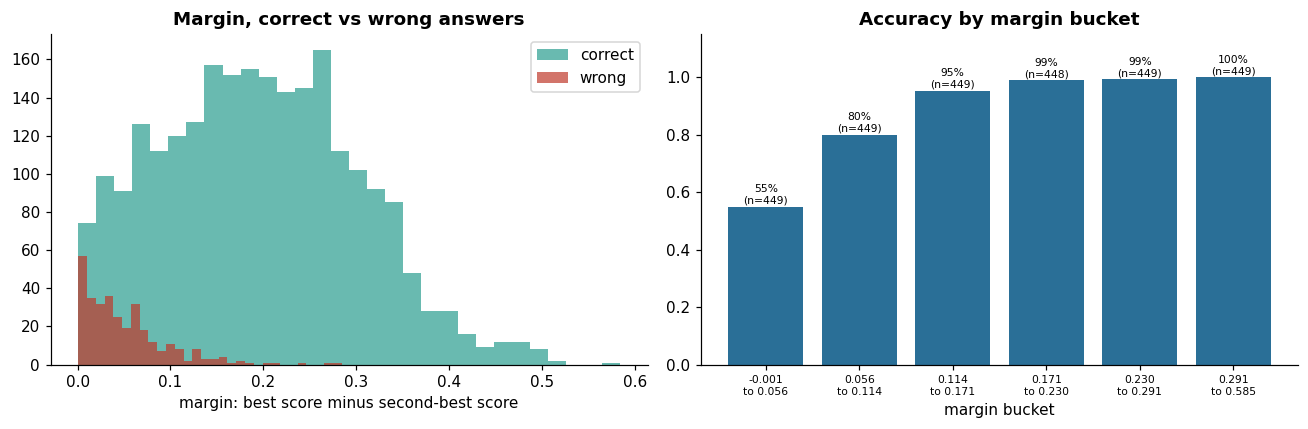

plots saved to /content/drive/MyDrive/Mfasha chatbot/results/plots


In [ ]:
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

SHOW = ["dev_seen", "dev_unseen"]
TOPIC_WORDS = 3
TOP_TOPICS = 12
COLORS = {"dev_seen": "#2a6f97", "dev_unseen": "#e07a1f", "test_seen": "#2a6f97", "test_unseen": "#e07a1f"}

PLOT_DIR = RESULTS_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


# per-question results, all in float32
S = np.asarray(S_ft, dtype=np.float32)
pred = S.argmax(axis=1)
gold_score = S[np.arange(len(S)), gold]
rk = (S >= gold_score[:, None]).sum(axis=1)
srt = np.sort(S, axis=1)
res_df = ev.assign(gold_idx=gold, pred_idx=pred, rk=rk, correct=(pred == gold),
                   top_score=srt[:, -1], margin=srt[:, -1] - srt[:, -2])
dv = res_df[res_df["split"].isin(SHOW)].copy()

# all systems compared
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = compare.pivot(index="system", columns="split", values="R@1")[SHOW].mean(axis=1).sort_values().index
for ax, metric in zip(axes, ["R@1", "R@10", "MRR@10"]):
    t = compare.pivot(index="system", columns="split", values=metric).loc[order, SHOW]
    y = np.arange(len(t))
    for k, sp in enumerate(SHOW):
        ax.barh(y + (k - 0.5) * 0.38, t[sp], 0.38, label=sp, color=COLORS[sp])
        for yy, v in zip(y + (k - 0.5) * 0.38, t[sp]):
            ax.text(v + 0.01, yy, f"{v:.2f}", va="center", fontsize=7)
    ax.set_yticks(y)
    ax.set_yticklabels(t.index if ax is axes[0] else [], fontsize=8)
    ax.set_xlim(0, 1.12)
    ax.set_title(metric, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8)
finish(fig, "1_systems_compared")

#  training curves
loss_file = RESULTS_DIR / "retrieval_loss_log.csv"
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
if loss_file.exists():
    loss_df = pd.read_csv(loss_file)
    ax[0].plot(loss_df["step"], loss_df["loss"], marker="o", color="#6a4c93")
    ax[0].set_yscale("log")
    ax[0].set_xlabel("step")
else:
    ax[0].text(0.5, 0.5, "no loss log yet\n(it is saved the next time the retriever is trained)",
               ha="center", va="center", transform=ax[0].transAxes)
ax[0].set_title("Training loss (log scale)", fontweight="bold")
for col, sp in [("dev_seen R@1", "dev_seen"), ("dev_unseen R@1", "dev_unseen")]:
    ax[1].plot(hist.index, hist[col], marker="o", label=sp, color=COLORS[sp])
    for x, v in zip(hist.index, hist[col]):
        ax[1].annotate(f"{v:.3f}", (x, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax[1].set_xticks(list(hist.index))
ax[1].set_title("Dev R@1 per epoch", fontweight="bold")
ax[1].set_xlabel("epoch")
ax[1].legend()
finish(fig, "2_training_curves")

# rank of the correct passage
bins = [(1, 1, "1"), (2, 2, "2"), (3, 3, "3"), (4, 5, "4-5"), (6, 10, "6-10"), (11, 10**9, ">10")]
fig, ax = plt.subplots(figsize=(8, 4.2))
bar_w = 0.38
for k, sp in enumerate(SHOW):
    r = dv.loc[dv["split"] == sp, "rk"].to_numpy()
    shares = [((r >= a) & (r <= b)).mean() for a, b, _ in bins]
    xs = np.arange(len(bins)) + (k - 0.5) * bar_w
    ax.bar(xs, shares, bar_w, label=sp, color=COLORS[sp])
    for x, s in zip(xs, shares):
        ax.text(x, s + 0.01, f"{s:.1%}", ha="center", fontsize=7)
ax.set_xticks(np.arange(len(bins)))
ax.set_xticklabels([b[2] for b in bins])
ax.set_xlabel("rank of the correct passage")
ax.set_ylabel("share of questions")
ax.set_title("Rank of the correct passage", fontweight="bold")
ax.legend()
finish(fig, "3_rank_distribution")

#  confusion matrix by topic
def topic(t):
    return " ".join(t.split(":", 1)[0].split()[:TOPIC_WORDS])


topics = np.array([topic(t) for t in passage_texts])
true_t, pred_t = topics[dv["gold_idx"].to_numpy()], topics[dv["pred_idx"].to_numpy()]
top_topic_names = pd.Series(true_t).value_counts().head(TOP_TOPICS).index.tolist()
lab = lambda a: np.where(np.isin(a, top_topic_names), a, "other")
labels = top_topic_names + ["other"]
cm = pd.crosstab(lab(true_t), lab(pred_t)).reindex(index=labels, columns=labels, fill_value=0)
cmn = cm.div(cm.sum(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(cmn.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm.iat[i, j] > 0:
            v = cmn.iat[i, j]
            ax.text(j, i, f"{v:.2f}\n({cm.iat[i, j]})", ha="center", va="center", fontsize=6,
                    color="white" if v > 0.5 else "black")
ax.set_xlabel("predicted topic")
ax.set_ylabel("true topic")
ax.set_title("Confusion matrix by topic (row-normalised, counts in brackets)", fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.04)
finish(fig, "4_confusion_topics")

#  most confused passage pairs
wrong_rows = dv[~dv["correct"]]
confused = Counter(zip(wrong_rows["gold_idx"], wrong_rows["pred_idx"])).most_common(12)
pair_df = pd.DataFrame([{
    "errors": n, "true_pid": passage_pids[g], "predicted_pid": passage_pids[p],
    "true_text": passage_texts[g][:70], "predicted_text": passage_texts[p][:70],
} for (g, p), n in confused])
print("MOST CONFUSED PASSAGE PAIRS (true -> predicted)")
print(pair_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([f"{r.true_pid} -> {r.predicted_pid}" for r in pair_df.itertuples()][::-1],
        pair_df["errors"][::-1], color="#c0392b")
ax.set_xlabel("wrong answers")
ax.set_title("Most confused passage pairs", fontweight="bold")
finish(fig, "5_confused_pairs")

# weakest passages
per = dv.groupby("gold_idx").agg(n=("correct", "size"), r1=("correct", "mean")).query("n >= 3")
weak = per.sort_values("r1").head(10).reset_index()
weak["pid"] = [passage_pids[i] for i in weak["gold_idx"]]
weak["text"] = [passage_texts[i][:80] for i in weak["gold_idx"]]
print("\nWEAKEST PASSAGES (at least 3 dev questions)")
print(weak[["pid", "n", "r1", "text"]].round(2).to_string(index=False))

#  confidence
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(dv.loc[dv["correct"], "margin"], bins=30, alpha=0.7, label="correct", color="#2a9d8f")
ax[0].hist(dv.loc[~dv["correct"], "margin"], bins=30, alpha=0.7, label="wrong", color="#c0392b")
ax[0].set_xlabel("margin: best score minus second-best score")
ax[0].set_title("Margin, correct vs wrong answers", fontweight="bold")
ax[0].legend()

dv["margin_bin"] = pd.qcut(dv["margin"], 6, duplicates="drop")
cal = dv.groupby("margin_bin", observed=True)["correct"].agg(["mean", "size"]).reset_index()
ax[1].bar(range(len(cal)), cal["mean"], color="#2a6f97")
ax[1].set_xticks(range(len(cal)))
ax[1].set_xticklabels([f"{b.left:.3f}\nto {b.right:.3f}" for b in cal["margin_bin"]], fontsize=7)
for i, (m, n) in enumerate(zip(cal["mean"], cal["size"])):
    ax[1].text(i, m + 0.01, f"{m:.0%}\n(n={n})", ha="center", fontsize=7)
ax[1].set_ylim(0, 1.15)
ax[1].set_title("Accuracy by margin bucket", fontweight="bold")
ax[1].set_xlabel("margin bucket")
finish(fig, "7_confidence")

print("plots saved to", PLOT_DIR)

In [12]:
model = SentenceTransformer(str(BEST_DIR), device=DEVICE, model_kwargs={"torch_dtype": torch.float16})
model.max_seq_length = 256

P_ft = model.encode([P_PRE + t for t in passage_texts], batch_size=16, normalize_embeddings=True).astype(np.float32)
np.save(EMB_DIR / "kinya_e5_passages.npy", P_ft)

Q_ft = model.encode([Q_PRE + q for q in questions], batch_size=64, normalize_embeddings=True).astype(np.float32)
S_ft = Q_ft @ P_ft.T

test_rows = pd.DataFrame(score(S_ft, "e5 fine-tuned"))
test_rows = test_rows[test_rows["split"].isin(["test_seen", "test_unseen"])]
test_rows.to_csv(RESULTS_DIR / "retrieval_final_test.csv", index=False)
print(test_rows.set_index("split").drop(columns="system").round(3).to_string())


def retrieve(question, k=CFG.top_k):
    q = model.encode([Q_PRE + question], normalize_embeddings=True).astype(np.float32)
    s = (q @ P_ft.T)[0]
    top = np.argsort(-s)[:k]
    return [(passage_pids[i], passage_texts[i], float(s[i])) for i in top]


demo = ev[ev["split"] == "test_unseen"].sample(3, random_state=CFG.seed)
for _, r in demo.iterrows():
    hits = retrieve(r["question"])
    rank = next((n + 1 for n, h in enumerate(hits) if h[0] == r["pos_pid"]), "not in top 5")
    print("question:", r["question"])
    print("right passage rank:", rank)
    print("top hit:", hits[0][1][:160], "\n")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

               R@1    R@5   R@10  MRR@10
split                                   
test_seen    0.893  0.990  0.994   0.936
test_unseen  0.866  0.988  0.994   0.923
question: nu ubuhe buryo umuhinzi abona ubwishingizi bw'ibihingwa?
right passage rank: 1
top hit: Umuhinzi ukeneye ubwishingizi bw'ibihingwa, agana ibigo bitanga ubwishingizi bifitanye amasezerano na MINAGRI cyangwa akegera agoronome w'umurenge ahingamo akam 

question: Umusaruro w'inkwavu uba uhagaze gute?
right passage rank: 1
top hit: Umusaruro w'inkwavuIyo inkwavu zirya ibyatsi gusa zishobora kugira kg 2 zimaze amezi atanu (ubwoko bwa kijyambere). Iyo zirya imvange y'ifu zipima kg 2 zimaze a 

question: Intama zororoka gute?
right passage rank: 1
top hit: Intama zororoka mu buryo bukurikira: Ku ntama 100 zimye, habyara 85; Ku ntama zibyara, havuka abana 140 ku nyarwanda, 180 ku za kijyambere; Intama ibangurirwa b 



In [13]:
import requests, time

NO_ANSWER = "Mbabarira, nta makuru mfite kuri icyo kibazo."

SYSTEM = (
    "You are an agriculture assistant for Rwandan farmers. "
    "Read the passages and pick the sentences that answer the question. "
    "Copy them exactly as written, word for word, in Kinyarwanda. Do not rewrite, translate, "
    "summarise or add anything. Use at most three sentences. "
    f"If no passage answers the question, reply exactly: {NO_ANSWER}"
)


# asks groq. waits and retries on rate limits, and on empty or cut-off replies
def ask_llm(question, hits, retries=4):
    context = "\n\n".join(f"[{i + 1}] {h[1]}" for i, h in enumerate(hits))
    messages = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": f"Passages:\n{context}\n\nQuestion: {question}"},
    ]
    for attempt in range(retries):
        try:
            r = requests.post(
                "https://api.groq.com/openai/v1/chat/completions",
                headers={"Authorization": f"Bearer {GROQ_API_KEY}"},
                json={"model": CFG.llm_model, "messages": messages,
                      "temperature": CFG.llm_temperature,
                      "max_tokens": 4096, "reasoning_effort": "low"},
                timeout=60,
            )
            if r.status_code == 429:
                time.sleep(5 * (attempt + 1))
                continue
            r.raise_for_status()
            choice = r.json()["choices"][0]
            text = (choice["message"].get("content") or "").strip()
            if not text or choice.get("finish_reason") == "length":
                time.sleep(1)
                continue
            return text
        except Exception as e:
            print("llm error:", str(e)[:150])
            time.sleep(2)
    return None


def tidy(text):
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = re.sub(r"[\u2010-\u2015]", "-", text)
    text = text.replace("*", "")
    # a heading stuck to the next word
    text = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", text)
    text = re.sub(r"(\d)\s*-\s*(\d)", r"\1-\2", text)
    return re.sub(r"\s+", " ", text).strip()


def answer(question):
    hits = retrieve(question)
    text = ask_llm(question, hits)
    return {"question": question, "answer": tidy(text) if text else None, "hits": hits}


def num_tokens(s):
    return {n.replace(",", ".") for n in re.findall(r"\d+(?:[.,]\d+)?", s)}


# whole-number match, so "5" is not accepted just because "15" is in the passage
def ungrounded_numbers(ans, hits):
    allowed = num_tokens(" ".join(h[1] for h in hits))
    return sorted(num_tokens(ans) - allowed)


print("answer functions ready")

answer functions ready


In [14]:
needed = ["pd", "re", "ev", "retrieve", "answer", "ungrounded_numbers", "NO_ANSWER", "CFG", "RESULTS_DIR"]
print({n: (n in globals()) for n in needed})

{'pd': True, 're': True, 'ev': True, 'retrieve': True, 'answer': True, 'ungrounded_numbers': True, 'NO_ANSWER': True, 'CFG': True, 'RESULTS_DIR': True}


In [20]:
sample = pd.concat([
    ev[ev["split"] == "dev_seen"].sample(3, random_state=CFG.seed),
    ev[ev["split"] == "dev_unseen"].sample(3, random_state=CFG.seed),
])
off_topic = [
    "Ni nde watwaye igikombe cy'isi cya 2022?",
    "Nakora nte porogaramu ya telefoni?",
    "Igiciro cy'itike ya bisi i Kigali ni angahe?",
]
todo = [(r["split"], r["question"]) for _, r in sample.iterrows()] + [("off_topic", q) for q in off_topic]


def pieces(text):
    return [p.strip() for p in re.split(r"(?<=[.!?;])\s+", text) if p.strip()]


def verbatim_share(ans, hits):
    context = tidy(" ".join(h[1] for h in hits))
    ps = pieces(tidy(ans))
    return sum(p in context for p in ps) / len(ps) if ps else 0.0


llm_rows = []
for split, q in todo:
    out = answer(q)
    ans = out["answer"] or ""
    refused = ans == NO_ANSWER
    share = 1.0 if refused else verbatim_share(ans, out["hits"])
    bad = [] if refused else ungrounded_numbers(ans, out["hits"])
    print("Q :", q)
    print("A :", ans)
    print(f"verbatim: {share:.0%} | refused: {refused} | numbers not in passages: {bad}\n")
    llm_rows.append({
        "split": split, "question": q, "answer": ans, "verbatim_share": round(share, 2),
        "numbers_not_in_passages": ", ".join(bad), "refused": refused,
        "top_passages": " || ".join(h[1][:300] for h in out["hits"][:2]),
        "fluency_1to5": "", "faithful_1to5": "",
    })

llm_res = pd.DataFrame(llm_rows)
llm_res.to_csv(RESULTS_DIR / "llm_samples_v3_to_rate.csv", index=False)
farm = llm_res[llm_res["split"] != "off_topic"]
print(f"farming questions: average verbatim share {farm['verbatim_share'].mean():.0%}")
print(f"off-topic questions refused: {llm_res[llm_res['split'] == 'off_topic']['refused'].sum()} of 3")

Q : Muraho neza nitwa Jean Claude ndi umuhinzi nshaka kubabaza amoko ya makadamiya ahingwa hano mu Rwanda?
A : Amoko ya makadamiya ni aya; Makadamiya ifite amoko abiri: hari ubwoko bufite igishishwa cyoroshye n'amavuta menshi (73-78 % aribwo Macadamia Integrifolia) arina yo yamamazwa mu Rwanda, muri Afrika no ku isi yose, n'ubwoko bufite igishishwa gikomeye n'amavuta make (Makadamia tetraphylia).
verbatim: 100% | refused: False | numbers not in passages: []

Q : Ese icyonnyi cy'imungu mubigori kirangwa niki?
A : Imungu ni agasimba kangiza ibigori mu bigega no mu bubiko. Imungu ikuze ifite uburebure buri hagati ya cm 3 na cm 3, 5 kandi isa n'umukara cyangwe se igihogo kijimye. Ku gice cy'igituza cyayo hagara utuntu tumeze nk'udutobore.
verbatim: 100% | refused: False | numbers not in passages: []

Q : Muraho neza nitwa Bugingo ndi umuhinzi ndashaka kubabaza uburyo bwo guhura ibihe?
A : Guhura ibihsyimbo ni igikorwa cyo kuvana imisogwe mu bishishwa. Ahenshi haracyakoreshwa uburyo bwo guh

In [21]:
import io, gc, re, json, time, pickle, random, jiwer
import pandas as pd
from huggingface_hub import hf_hub_download


def clean_text(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"(?<=\w)'\s+(?=\w)", "'", t)
    t = re.sub(r"(\.\s*){2,}", "... ", t)
    t = re.sub(r"\s+([,.;:!?)\]])", r"\1", t)
    t = re.sub(r"([(\[])\s+", r"\1", t)
    t = re.sub(r"\s+", " ", t)
    return t.strip()

In [22]:
import io, json, pickle, jiwer
import soundfile as sf, librosa
from concurrent.futures import ThreadPoolExecutor
from huggingface_hub import list_repo_files

HELD_OUT_VOICE = "rw_ag_tts_male2"
N_TEST = 200
TEST_CACHE = DATA_DIR / "asr_test_male2.pkl"

files = list_repo_files(CFG.tts_repo, repo_type="dataset")
wav_set = {f for f in files if f.lower().endswith(".wav")}

tables = []
for tsv in sorted(f for f in files if f.endswith(".tsv")):
    path = hf_hub_download(CFG.tts_repo, tsv, repo_type="dataset")
    raw = pd.read_csv(path, sep="\t", header=None, quoting=3, dtype=str,
                      keep_default_na=False, on_bad_lines="skip")
    df = raw.iloc[:, :2].copy()
    df.columns = ["id", "text"]
    df["id"] = df["id"].str.replace(".wav", "", regex=False).str.strip()
    df["voice"] = tsv[:-4]
    df["wav"] = df["voice"] + "/" + df["id"] + ".wav"
    tables.append(df)

clips = pd.concat(tables, ignore_index=True)
clips = clips[clips["wav"].isin(wav_set)].copy()
clips["key"] = clips["text"].map(lambda t: re.sub(r"\s+", " ", t.strip().lower()))


def has_digit(t):
    return any(ch.isdigit() for ch in t)


ok = clips[(clips["text"].str.strip().str.len() > 10)
           & ~clips["text"].map(has_digit)
           & (clips["text"].str.split().str.len() <= 40)]

held = ok[ok["voice"] == HELD_OUT_VOICE].drop_duplicates("key")
test_keys = sorted(held["key"])
random.Random(CFG.seed).shuffle(test_keys)
test_keys = test_keys[:N_TEST]
(DATA_DIR / "asr_test_keys.json").write_text(json.dumps(test_keys, ensure_ascii=False), encoding="utf-8")
test_rows = held[held["key"].isin(test_keys)].reset_index(drop=True)
print(len(test_rows), "test sentences from", HELD_OUT_VOICE)


def load_wav(path):
    local = hf_hub_download(CFG.tts_repo, path, repo_type="dataset")
    y, sr = sf.read(local, dtype="float32")
    if y.ndim > 1:
        y = y.mean(1)
    if sr != 16000:
        y = librosa.resample(y, orig_sr=sr, target_sr=16000)
    return y


if TEST_CACHE.exists():
    with open(TEST_CACHE, "rb") as f:
        test = pickle.load(f)
else:
    with ThreadPoolExecutor(6) as ex:
        audios = list(ex.map(load_wav, test_rows["wav"]))
    test = [{"audio": a, "text": t, "id": i} for a, t, i in zip(audios, test_rows["text"], test_rows["id"])]
    with open(TEST_CACHE, "wb") as f:
        pickle.dump(test, f)

print(len(test), "clips,", round(sum(len(c["audio"]) for c in test) / 16000 / 60), "minutes of audio")


def norm_strict(t):
    t = t.lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


def norm_loose(t):
    return norm_strict(t).replace("'", "")


def messy(t):
    return bool(re.search(r"[()/\[\]]", t)) or any(ord(ch) > 127 and ch not in "\u2019\u2018" for ch in t)


refs = [clean_text(c["text"]) for c in test]
is_clean = np.array([not messy(c["text"]) for c in test])


def wer_of(hyps, idx, norm):
    return jiwer.wer([norm(refs[i]) for i in idx], [norm(hyps[i]) for i in idx])


def report(name, hyps):
    everyone = np.arange(len(refs))
    return {
        "system": name,
        "WER": wer_of(hyps, everyone, norm_strict),
        "WER no apostrophes": wer_of(hyps, everyone, norm_loose),
        "CER": jiwer.cer([norm_strict(r) for r in refs], [norm_strict(h) for h in hyps]),
        "WER clean text only": wer_of(hyps, np.where(is_clean)[0], norm_strict),
    }


def run_mms():
    from transformers import Wav2Vec2ForCTC, AutoProcessor
    proc = AutoProcessor.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang)
    m = Wav2Vec2ForCTC.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang,
                                       ignore_mismatched_sizes=True).to(DEVICE).half().eval()
    out = []
    for c in test:
        x = proc(c["audio"], sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE).half()
        with torch.no_grad():
            out.append(proc.decode(m(x).logits.argmax(-1)[0]))
    del m
    return out


# only the stock mms adapter here. the sunbird model needs access approval on hugging face
systems = {"MMS-1b-all (kin adapter)": run_mms}
asr_rows, all_hyps = [], {}
for name, fn in systems.items():
    try:
        t0 = time.time()
        hyps = fn()
        print(f"{name}: done in {time.time() - t0:.0f} s")
    except Exception as e:
        print(f"{name} failed:", str(e)[:300])
        continue
    finally:
        gc.collect()
        torch.cuda.empty_cache()
    all_hyps[name] = hyps
    asr_rows.append(report(name, hyps))

res = pd.DataFrame(asr_rows).set_index("system")
print(res.round(3).to_string())
res.to_csv(RESULTS_DIR / "asr_baselines.csv")
pd.DataFrame({"reference": refs, **all_hyps}).to_csv(RESULTS_DIR / "asr_baseline_outputs.csv", index=False)

for i in np.random.default_rng(CFG.seed).choice(len(test), 4, replace=False):
    print("\nref:", refs[i])
    for name, hyps in all_hyps.items():
        print(f"{name[:10]:10s}:", hyps[i])

rw_ag_tts_female.tsv:   0%|          | 0.00/471k [00:00<?, ?B/s]

rw_ag_tts_female2.tsv:   0%|          | 0.00/314k [00:00<?, ?B/s]

rw_ag_tts_male.tsv:   0%|          | 0.00/471k [00:00<?, ?B/s]

rw_ag_tts_male2.tsv:   0%|          | 0.00/299k [00:00<?, ?B/s]

200 test sentences from rw_ag_tts_male2
200 clips, 19 minutes of audio


...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

adapter.kin.safetensors: reconstructing file:   0%|          |  0.00B / 9.36MB            

adapter.kin.safetensors: downloading bytes:           |  0.00B            

MMS-1b-all (kin adapter): done in 87 s
                            WER  WER no apostrophes    CER  WER clean text only
system                                                                         
MMS-1b-all (kin adapter)  0.301               0.293  0.063                0.292

ref: Kugira isuku ku mukamyi n'ibikoresho byo gukama
MMS-1b-all: kugira isuku ku mukamyi n'ibikoresho byo gukama

ref: Ibimenyetso birananga indwara y'akaribata (Anthracnose) ko muri puwavuro
MMS-1b-all: ibimenyetso biranga indwara y'akaribata anarakinose ko muri puwavuro

ref: Iyo umworozi akurikirana neza umunsi ku w'undi inkoko ze, ashobora kubona impinduka akamenya niba hari ibitagendaneza arebeye kumatotoro.
MMS-1b-all: iyo imworoza akurikirana neza umunsi ku wundi nkoko ze ashobora kubona impinduka akamenya niba hari ibitagenda neza arebeye ku matotoro

ref: INKA: Inka z'ibyimanyi n'inka z'inzungu
MMS-1b-all: inka inka zibyimanye n'inka z'inzungu


In [ ]:
import collections

N_TRAIN_SENT = 3000
N_DEV_SENT = 100
PER_SENT = 2
TRAIN_VOICES = ["rw_ag_tts_female", "rw_ag_tts_female2", "rw_ag_tts_male"]
TRAIN_CACHE = DATA_DIR / "asr_train_dev.pkl"


def bad_label(t):
    return "/" in t or any(ord(ch) > 127 and ch not in "\u2019\u2018" for ch in t)


# same cleaning as the training labels, so a test sentence can never slip into training
test_nkeys = {norm_strict(clean_text(c["text"])) for c in test}

pool = ok[ok["voice"].isin(TRAIN_VOICES)].copy()
pool["label"] = pool["text"].map(lambda t: norm_strict(clean_text(t)))
pool = pool[~pool["label"].isin(test_nkeys) & ~pool["text"].map(bad_label) & (pool["label"].str.len() > 5)]

sentences = sorted(pool["label"].unique())
random.Random(CFG.seed).shuffle(sentences)
dev_s = set(sentences[:N_DEV_SENT])
train_s = set(sentences[N_DEV_SENT:N_DEV_SENT + N_TRAIN_SENT])

shuffled = pool.sample(frac=1, random_state=CFG.seed)
dev_rows = shuffled[shuffled["label"].isin(dev_s)].drop_duplicates("label").assign(split="dev")
train_rows = shuffled[shuffled["label"].isin(train_s)].groupby("label").head(PER_SENT).assign(split="train")
use = pd.concat([train_rows, dev_rows]).reset_index(drop=True)
print(len(use), "clips to fetch |", use["split"].value_counts().to_dict())
assert not (set(use["label"]) & test_nkeys), "a test sentence is in the training data"

counter = [0]


def fetch_clip(path):
    for attempt in range(5):
        try:
            y = load_wav(path)
            counter[0] += 1
            if counter[0] % 500 == 0:
                print("  fetched", counter[0], "of", len(use))
            return y
        except Exception:
            time.sleep(3 * (attempt + 1))
    return None


if TRAIN_CACHE.exists():
    with open(TRAIN_CACHE, "rb") as f:
        data = pickle.load(f)
    print("loaded from Drive")
    # a cache built before the leak fix may hold test sentences, so check it
    leaked = [c for c in data["train"] + data["dev"] if c["text"] in test_nkeys]
    print("test sentences found in the cached training data:", len(leaked))
    if leaked:
        data = {s: [c for c in items if c["text"] not in test_nkeys] for s, items in data.items()}
        print("removed them from the loaded data (the pickle on Drive is unchanged)")
else:
    t0 = time.time()
    with ThreadPoolExecutor(24) as ex:
        audios = list(ex.map(fetch_clip, use["wav"]))
    print(f"download finished in {time.time() - t0:.0f} s")

    failed = sum(y is None for y in audios)
    print("failed downloads:", failed)
    assert failed < 0.05 * len(use), "too many clips failed, run this cell again"

    data = {"train": [], "dev": []}
    filtered = 0
    for (_, r), y in zip(use.iterrows(), audios):
        if y is None or len(y) < 8000 or len(y) > 16000 * 20:
            filtered += 1
            continue
        pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16)
        data[r["split"]].append({"audio": pcm, "text": r["label"], "voice": r["voice"], "id": r["id"]})
    print("left out (failed, too short or too long):", filtered)
    with open(TRAIN_CACHE, "wb") as f:
        pickle.dump(data, f)
    print("saved to Drive")

for s, items in data.items():
    hours = sum(len(c["audio"]) for c in items) / 16000 / 3600
    voices_n = pd.Series([c["voice"] for c in items]).value_counts().to_dict()
    print(f"{s:5s}: {len(items)} clips | {len({c['text'] for c in items})} sentences | {hours:.1f} h | {voices_n}")

char_counts = collections.Counter("".join(c["text"] for c in data["train"]))
odd = {ch: n for ch, n in char_counts.items() if not (ch.isascii() and (ch.isalpha() or ch in "' "))}
print("unusual characters in the labels:", odd if odd else "none")

6087 clips to fetch | {'train': 5987, 'dev': 100}
loaded from Drive
test sentences found in the cached training data: 0
train: 2000 clips | 2000 sentences | 2.4 h | {'rw_ag_tts_female': 757, 'rw_ag_tts_male': 730, 'rw_ag_tts_female2': 513}
dev  : 100 clips | 100 sentences | 0.1 h | {'rw_ag_tts_male': 45, 'rw_ag_tts_female': 38, 'rw_ag_tts_female2': 17}
unusual characters in the labels: none


In [24]:
from scipy.signal import resample_poly
from transformers import Wav2Vec2ForCTC, AutoProcessor, get_linear_schedule_with_warmup

EPOCHS = 6
PATIENCE = 2
LR = 2e-4
MAX_BATCH_SEC = 40

RETRAIN_ASR = False

ADAPTER_DIR = MODELS_DIR / "mms-kin-adapter"
ADAPTER_DIR.mkdir(exist_ok=True)
BEST_PT = ADAPTER_DIR / "best.pt"
DONE_FLAG = ADAPTER_DIR / "training_done.txt"   # written only when training ends normally

need_asr_training = RETRAIN_ASR or not DONE_FLAG.exists()

required = ("data", "test", "report", "asr_rows", "refs", "norm_strict") if need_asr_training else ("test",)
for name in required:
    assert name in globals(), f"'{name}' is missing, run the earlier cells first"


def load_asr():
    p = AutoProcessor.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang)
    m = Wav2Vec2ForCTC.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang,
                                       ignore_mismatched_sizes=True).to(DEVICE)
    return p, m


def trainable_state(model):
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}


if need_asr_training:
    gc.collect()
    torch.cuda.empty_cache()
    rnd = random.Random(CFG.seed)
    np_rng = np.random.default_rng(CFG.seed)

    proc, asr_model = load_asr()
    asr_model.config.layerdrop = 0.0
    asr_model.config.ctc_zero_infinity = True

    for n, p in asr_model.named_parameters():
        p.requires_grad = ("adapter" in n) or n.startswith("lm_head")
    params = [p for p in asr_model.parameters() if p.requires_grad]
    n_train, n_all = sum(p.numel() for p in params), sum(p.numel() for p in asr_model.parameters())
    print(f"training {n_train / 1e6:.1f}M of {n_all / 1e6:.0f}M parameters ({100 * n_train / n_all:.2f}%)")

    unk = proc.tokenizer.unk_token_id
    n_unk = sum(unk in proc.tokenizer(c["text"]).input_ids for c in data["train"])
    print("train clips with a character the model does not know:", n_unk)

    def to_float(a):
        return a.astype(np.float32) / 32768.0 if a.dtype == np.int16 else a.astype(np.float32)

    def make_batches(items, max_sec, shuffle):
        idx = list(range(len(items)))
        if shuffle:
            rnd.shuffle(idx)
        batches = []
        for start in range(0, len(idx), 256):
            chunk = sorted(idx[start:start + 256], key=lambda i: len(items[i]["audio"]))
            cur, longest = [], 0
            for i in chunk:
                n = len(items[i]["audio"])
                if cur and max(longest, n) * (len(cur) + 1) > max_sec * 16000:
                    batches.append(cur)
                    cur, longest = [], 0
                cur.append(i)
                longest = max(longest, n)
            if cur:
                batches.append(cur)
        if shuffle:
            rnd.shuffle(batches)
        return batches

    def augment(y):
        if rnd.random() < 0.3:
            y = resample_poly(resample_poly(y, 1, 2), 2, 1)[:len(y)].astype(np.float32)
        if rnd.random() < 0.5:
            snr = rnd.uniform(8, 30)
            power = np.mean(y ** 2) + 1e-8
            y = y + np_rng.standard_normal(len(y)).astype(np.float32) * np.sqrt(power / 10 ** (snr / 10))
        return np.clip(y, -1, 1)

    def collate(items, idxs, train):
        wavs = [augment(to_float(items[i]["audio"])) if train else to_float(items[i]["audio"]) for i in idxs]
        feats = proc.feature_extractor(wavs, sampling_rate=16000, padding=True,
                                       return_attention_mask=True, return_tensors="pt")
        ids = [proc.tokenizer(items[i]["text"]).input_ids for i in idxs]
        labels = torch.full((len(ids), max(map(len, ids))), -100)
        for r, seq in enumerate(ids):
            labels[r, :len(seq)] = torch.tensor(seq)
        return feats.input_values.to(DEVICE), feats.attention_mask.to(DEVICE), labels.to(DEVICE)

    @torch.no_grad()
    def transcribe(items):
        asr_model.eval()
        out = [None] * len(items)
        for idxs in make_batches(items, 60, shuffle=False):
            x, am, _ = collate(items, idxs, train=False)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = asr_model(input_values=x, attention_mask=am).logits
            for i, text in zip(idxs, proc.batch_decode(logits.argmax(-1))):
                out[i] = text.strip()
        return out

    def dev_wer():
        hyps = transcribe(data["dev"])
        return jiwer.wer([norm_strict(c["text"]) for c in data["dev"]], [norm_strict(h) for h in hyps])

    opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
    steps_per_epoch = len(make_batches(data["train"], MAX_BATCH_SEC, shuffle=True))
    total_steps = int(EPOCHS * steps_per_epoch * 1.05)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler()
    print(f"{steps_per_epoch} steps per epoch")

    history = [{"epoch": 0, "dev_wer": dev_wer(), "train_loss": None}]
    print(f"before training: dev WER {history[0]['dev_wer']:.3f}")
    best = {"wer": history[0]["dev_wer"], "epoch": 0, "bad": 0}
    best_state = trainable_state(asr_model)      # the untrained adapter, kept in memory only

    for epoch in range(1, EPOCHS + 1):
        asr_model.train()
        t0, batch_losses = time.time(), []
        for step, idxs in enumerate(make_batches(data["train"], MAX_BATCH_SEC, shuffle=True), 1):
            x, am, y = collate(data["train"], idxs, train=True)
            with torch.autocast("cuda", dtype=torch.float16):
                batch_loss = asr_model(input_values=x, attention_mask=am, labels=y).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(batch_loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            batch_losses.append(batch_loss.item())
            if step % 100 == 0:
                print(f"  epoch {epoch} step {step}/{steps_per_epoch} loss {np.mean(batch_losses[-100:]):.3f} | {time.time() - t0:.0f} s")

        wer = dev_wer()
        history.append({"epoch": epoch, "dev_wer": wer, "train_loss": float(np.mean(batch_losses))})
        print(f"epoch {epoch}: train loss {np.mean(batch_losses):.3f} | dev WER {wer:.3f} | {time.time() - t0:.0f} s")
        if wer < best["wer"]:
            best.update(wer=wer, epoch=epoch, bad=0)
            best_state = trainable_state(asr_model)
            torch.save(best_state, BEST_PT)      # saved on every gain, so a disconnect keeps progress
            print("  new best, saved")
        else:
            best["bad"] += 1
            if best["bad"] >= PATIENCE:
                print(f"  no gain for {PATIENCE} epochs, stopping")
                break

    # keep the best weights, even if that is the untrained adapter
    torch.save(best_state, BEST_PT)
    asr_model.load_state_dict(best_state, strict=False)
    DONE_FLAG.write_text(f"best epoch {best['epoch']}, dev WER {best['wer']:.3f}")
    pd.DataFrame(history).to_csv(RESULTS_DIR / "asr_finetune_history.csv", index=False)
    print("best epoch:", best["epoch"], "| dev WER", round(best["wer"], 3))
    if best["epoch"] == 0:
        print("training did not beat the starting adapter on dev, so the starting adapter is kept")

    hyps = transcribe(test)
    asr_rows = [r for r in asr_rows if r["system"] != "MMS adapter fine-tuned"]
    asr_rows.append(report("MMS adapter fine-tuned", hyps))
    res = pd.DataFrame(asr_rows).set_index("system")
    print("\nTEST SET (held-out voice, 200 clips)")
    print(res.round(3).to_string())
    res.to_csv(RESULTS_DIR / "asr_finetuned_test.csv")
    pd.DataFrame({"reference": refs, "fine-tuned": hyps}).to_csv(RESULTS_DIR / "asr_finetuned_outputs.csv", index=False)
else:
    proc, asr_model = load_asr()
    asr_model.load_state_dict(torch.load(BEST_PT, map_location="cpu"), strict=False)
    print("finished adapter found:", DONE_FLAG.read_text())

asr_model.eval()


# one clip to text. audio can be a file path or a float32 array already at 16 khz
def speech_to_text(audio):
    if isinstance(audio, (str, Path)):
        audio, _ = librosa.load(str(audio), sr=16000, mono=True)
    x = proc.feature_extractor(audio, sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        logits = asr_model(input_values=x).logits
    return proc.decode(logits.argmax(-1)[0]).strip()


# the one function the app will call, for typed text or for a voice clip
def chat(text=None, audio=None):
    heard = speech_to_text(audio) if audio is not None else None
    question = ((heard if audio is not None else text) or "").strip()
    if not question:
        return {"heard": heard, "question": None, "answer": None, "sources": []}
    if "answer" not in globals():
        return {"heard": heard, "question": question, "answer": None, "sources": [],
                "note": "the text cells are not loaded, so there is no answer yet"}
    out = answer(question)
    return {"heard": heard, "question": question, "answer": out["answer"],
            "sources": [(h[0], round(h[2], 3)) for h in out["hits"]]}


# quick check on one test clip
print("\nreference:", test[0]["text"])
print("heard    :", speech_to_text(test[0]["audio"]))
if "answer" in globals():
    print(chat(text="Intama zororoka gute?"))

Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

finished adapter found: best epoch 3, dev WER 0.284

reference: Gutera ubwoko bw’imbuto y’ibirayi bwihanganira iyo ndwara
heard    : gutera ubwoko bw'imbuto y'ibirayi bwihanganira iyo ndwara
{'heard': None, 'question': 'Intama zororoka gute?', 'answer': 'Intama zororoka mu buryo bukurikira: Ku ntama 100 zimye, habyara 85; Ku ntama zibyara, havuka abana 140 ku nyarwanda, 180 ku za kijyambere. Intama ihaka iminsi 149-152, (amezi 5); Yonsa amezi atatu, ishobora rero kubyara buri mezi 9 iyo yorowe kijyambere.', 'sources': [('A712T526', 0.777), ('A714T528', 0.541), ('A648T461', 0.429), ('A715T529', 0.396), ('A055T041', 0.384)]}


In [25]:

def speech_to_text(audio):
    if isinstance(audio, (str, Path)):
        audio, _ = librosa.load(str(audio), sr=16000, mono=True)
    x = proc.feature_extractor(audio, sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE)
    with torch.no_grad(), torch.autocast(DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda")):
        logits = asr_model(input_values=x).logits
    return proc.decode(logits.argmax(-1)[0]).strip()


def chat(text=None, audio=None):
    heard = speech_to_text(audio) if audio is not None else None
    question = ((heard if audio is not None else text) or "").strip()
    if not question:
        return {"heard": heard, "question": None, "answer": None, "sources": []}
    if "answer" not in globals():
        return {"heard": heard, "question": question, "answer": None, "sources": [],
                "note": "the text cells are not loaded, so there is no answer yet"}
    out = answer(question)
    ans = out["answer"]
    bad = ungrounded_numbers(ans, out["hits"]) if ans and ans != NO_ANSWER else []
    if bad:
        ans = NO_ANSWER
    return {"heard": heard, "question": question, "answer": ans, "ungrounded_numbers": bad,
            "sources": [(h[0], round(h[2], 3)) for h in out["hits"]]}


print(chat(text="Intama zororoka gute?"))

{'heard': None, 'question': 'Intama zororoka gute?', 'answer': 'Intama zororoka mu buryo bukurikira: Ku ntama 100 zimye, habyara 85; Ku ntama zibyara, havuka abana 140 ku nyarwanda, 180 ku za kijyambere. Intama ihaka iminsi 149-152, (amezi 5); Yonsa amezi atatu, ishobora rero kubyara buri mezi 9 iyo yorowe kijyambere.', 'ungrounded_numbers': [], 'sources': [('A712T526', 0.777), ('A714T528', 0.541), ('A648T461', 0.429), ('A715T529', 0.396), ('A055T041', 0.384)]}


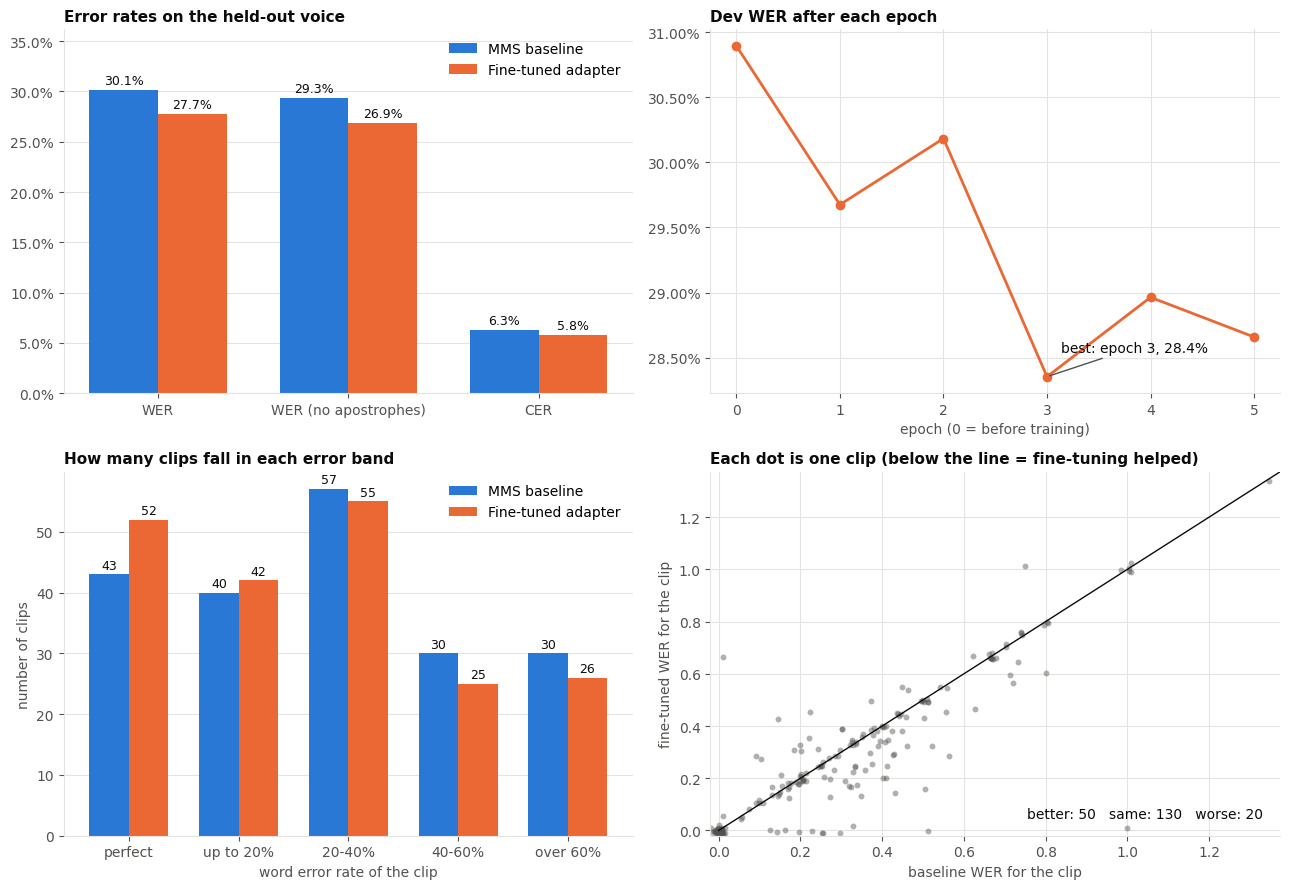

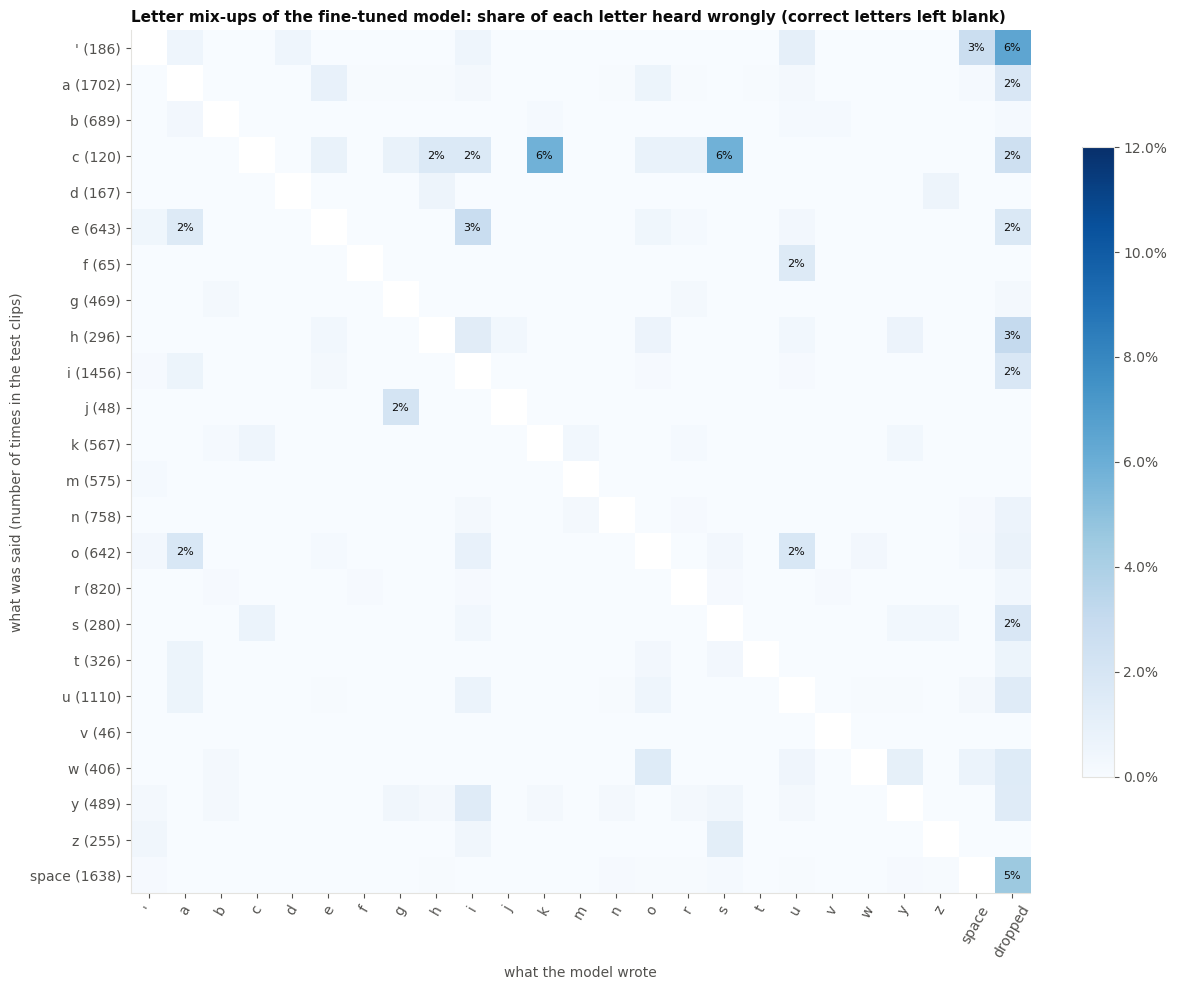

most common letter mix-ups (said -> written):
  e -> i: 18
  a -> e: 15
  o -> u: 12
  o -> a: 12
  r -> l: 11
  a -> o: 11
  e -> a: 10
  i -> a: 9
  u -> i: 8
  c -> s: 7
letters it most often left out: [('space', 74), ('a', 31), ('i', 26), ('u', 16), ("'", 12)]
letters it most often added: [('space', 58), ('i', 39), ('a', 23), ("'", 20), ('y', 17)]


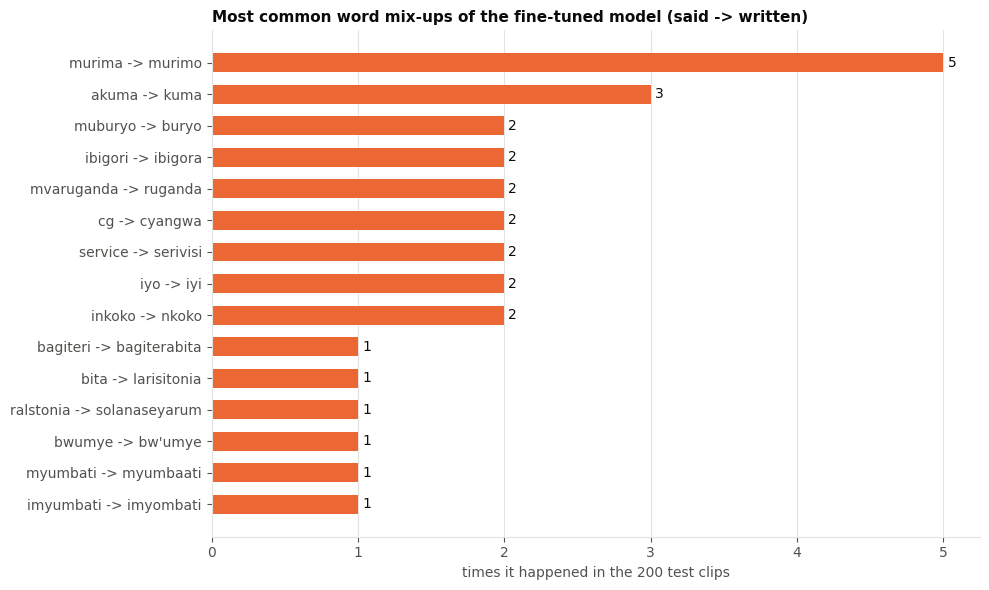


what happened to each reference word:
  baseline  : correct 1336 | wrong word 426 | dropped 76 | extra words 52
  fine-tuned: correct 1375 | wrong word 404 | dropped 59 | extra words 47
words it dropped most often: [('ari', 2), ('mildew', 2), ('ingurube', 2), ('hishingirwa', 2), ('iki', 2), ('solanacearum', 1), ('itunganijwe', 1), ('aho', 1)]

plots saved to /content/drive/MyDrive/Mfasha chatbot/results/plots


In [ ]:
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from collections import Counter
import jiwer

BASE_C, TUNED_C = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.facecolor": "white",
})
PLOT_DIR = RESULTS_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)


def norm(t):
    t = str(t).lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


base = pd.read_csv(RESULTS_DIR / "asr_baseline_outputs.csv").fillna("")
tuned = pd.read_csv(RESULTS_DIR / "asr_finetuned_outputs.csv").fillna("")
asr_hist = pd.read_csv(RESULTS_DIR / "asr_finetune_history.csv")
assert list(base["reference"]) == list(tuned["reference"]), "the two result files are not in the same order"

keep_i = [i for i, t in enumerate(tuned["reference"]) if norm(t)]
ref = [norm(tuned["reference"][i]) for i in keep_i]
hyp_b = [norm(base["MMS-1b-all (kin adapter)"][i]) for i in keep_i]
hyp_t = [norm(tuned["fine-tuned"][i]) for i in keep_i]


def scores(h):
    return {
        "WER": jiwer.wer(ref, h),
        "WER (no apostrophes)": jiwer.wer([r.replace("'", "") for r in ref], [x.replace("'", "") for x in h]),
        "CER": jiwer.cer(ref, h),
    }


sb, st = scores(hyp_b), scores(hyp_t)
clip_b = np.array([jiwer.wer(r, h) for r, h in zip(ref, hyp_b)])
clip_t = np.array([jiwer.wer(r, h) for r, h in zip(ref, hyp_t)])


def bands(w):
    out = np.zeros(5, int)
    for v in w:
        out[0 if v == 0 else 1 if v <= 0.2 else 2 if v <= 0.4 else 3 if v <= 0.6 else 4] += 1
    return out


fig, ax = plt.subplots(2, 2, figsize=(13, 9))

a = ax[0, 0]
names = list(sb)
x, w = np.arange(len(names)), 0.36
b1 = a.bar(x - w / 2, [sb[n] for n in names], w, color=BASE_C, label="MMS baseline")
b2 = a.bar(x + w / 2, [st[n] for n in names], w, color=TUNED_C, label="Fine-tuned adapter")
for bars in (b1, b2):
    a.bar_label(bars, labels=[f"{v.get_height():.1%}" for v in bars], padding=2, fontsize=9, color=INK)
a.set_xticks(x, names)
a.yaxis.set_major_formatter(PercentFormatter(1))
a.set_ylim(0, max(sb.values()) * 1.2)
a.set_title("Error rates on the held-out voice")
a.legend(frameon=False)
a.grid(axis="x", visible=False)

b = ax[0, 1]
b.plot(asr_hist["epoch"], asr_hist["dev_wer"], color=TUNED_C, lw=2, marker="o", ms=6)
bi = asr_hist["dev_wer"].idxmin()
b.annotate(f"best: epoch {int(asr_hist['epoch'][bi])}, {asr_hist['dev_wer'][bi]:.1%}",
           (asr_hist["epoch"][bi], asr_hist["dev_wer"][bi]), xytext=(10, 18), textcoords="offset points",
           color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
b.yaxis.set_major_formatter(PercentFormatter(1))
b.set_xlabel("epoch (0 = before training)")
b.set_title("Dev WER after each epoch")

c = ax[1, 0]
labels = ["perfect", "up to 20%", "20-40%", "40-60%", "over 60%"]
xc = np.arange(5)
c1 = c.bar(xc - w / 2, bands(clip_b), w, color=BASE_C, label="MMS baseline")
c2 = c.bar(xc + w / 2, bands(clip_t), w, color=TUNED_C, label="Fine-tuned adapter")
for bars in (c1, c2):
    c.bar_label(bars, padding=2, fontsize=9, color=INK)
c.set_xticks(xc, labels)
c.set_xlabel("word error rate of the clip")
c.set_ylabel("number of clips")
c.set_title("How many clips fall in each error band")
c.legend(frameon=False)
c.grid(axis="x", visible=False)

ax_d = ax[1, 1]
jit = np.random.default_rng(0).normal(0, 0.008, (2, len(clip_b)))
ax_d.scatter(clip_b + jit[0], clip_t + jit[1], s=18, color=MUTED, alpha=0.45, linewidths=0)
top = max(1.0, clip_b.max(), clip_t.max()) * 1.03
ax_d.plot([0, top], [0, top], color=INK, lw=1)
ax_d.set_xlim(-0.02, top)
ax_d.set_ylim(-0.02, top)
better, worse = int((clip_t < clip_b).sum()), int((clip_t > clip_b).sum())
same = len(clip_b) - better - worse
ax_d.text(0.97, 0.05, f"better: {better}   same: {same}   worse: {worse}", transform=ax_d.transAxes,
          ha="right", color=INK)
ax_d.set_xlabel("baseline WER for the clip")
ax_d.set_ylabel("fine-tuned WER for the clip")
ax_d.set_title("Each dot is one clip (below the line = fine-tuning helped)")

plt.tight_layout()
plt.savefig(PLOT_DIR / "asr_overview.png", dpi=200, facecolor="white")
plt.show()

out = jiwer.process_characters(ref, hyp_t)
hit, sub, drop, extra = Counter(), Counter(), Counter(), Counter()
for i, chunks in enumerate(out.alignments):
    r, h = out.references[i], out.hypotheses[i]
    for ch in chunks:
        n_ref, n_hyp = ch.ref_end_idx - ch.ref_start_idx, ch.hyp_end_idx - ch.hyp_start_idx
        if ch.type == "equal":
            for k in range(n_ref):
                hit[r[ch.ref_start_idx + k]] += 1
        elif ch.type == "substitute":
            for k in range(n_ref):
                sub[(r[ch.ref_start_idx + k], h[ch.hyp_start_idx + k])] += 1
        elif ch.type == "delete":
            for k in range(n_ref):
                drop[r[ch.ref_start_idx + k]] += 1
        elif ch.type == "insert":
            for k in range(n_hyp):
                extra[h[ch.hyp_start_idx + k]] += 1

total = Counter()
for ch, n in hit.items():
    total[ch] += n
for (r_ch, _), n in sub.items():
    total[r_ch] += n
for ch, n in drop.items():
    total[ch] += n

char_list = [c for c in sorted(total) if total[c] >= 40 and c != " "] + [" "]
cols = char_list + ["dropped"]
mat = np.full((len(char_list), len(cols)), np.nan)
for i, r_ch in enumerate(char_list):
    for j, h_ch in enumerate(char_list):
        if r_ch != h_ch:
            mat[i, j] = sub[(r_ch, h_ch)] / total[r_ch]
    mat[i, -1] = drop[r_ch] / total[r_ch]

show = lambda c: "space" if c == " " else c
fig, axm = plt.subplots(figsize=(12, 10))
vmax = max(0.12, np.nanpercentile(mat, 99))
im = axm.imshow(mat, cmap="Blues", vmin=0, vmax=vmax)
axm.set_xticks(range(len(cols)), [show(c) for c in cols], rotation=60)
axm.set_yticks(range(len(char_list)), [f"{show(c)} ({total[c]})" for c in char_list])
axm.grid(False)
for i in range(len(char_list)):
    for j in range(len(cols)):
        v = mat[i, j]
        if not np.isnan(v) and v >= 0.015:
            axm.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                     color="white" if v > 0.6 * vmax else INK)
axm.set_xlabel("what the model wrote")
axm.set_ylabel("what was said (number of times in the test clips)")
axm.set_title("Letter mix-ups of the fine-tuned model: share of each letter heard wrongly (correct letters left blank)")
fig.colorbar(im, ax=axm, fraction=0.03, format=PercentFormatter(1))
plt.tight_layout()
plt.savefig(PLOT_DIR / "asr_char_confusion.png", dpi=200, facecolor="white")
plt.show()

print("most common letter mix-ups (said -> written):")
for (r_ch, h_ch), n in sub.most_common(10):
    print(f"  {show(r_ch)} -> {show(h_ch)}: {n}")
print("letters it most often left out:", [(show(c), n) for c, n in drop.most_common(5)])
print("letters it most often added:", [(show(c), n) for c, n in extra.most_common(5)])

wout = jiwer.process_words(ref, hyp_t)
word_pairs, missed = Counter(), Counter()
for i, chunks in enumerate(wout.alignments):
    r, h = wout.references[i], wout.hypotheses[i]
    for ch in chunks:
        if ch.type == "substitute":
            for k in range(ch.ref_end_idx - ch.ref_start_idx):
                word_pairs[(r[ch.ref_start_idx + k], h[ch.hyp_start_idx + k])] += 1
        elif ch.type == "delete":
            for k in range(ch.ref_end_idx - ch.ref_start_idx):
                missed[r[ch.ref_start_idx + k]] += 1

top_pairs = word_pairs.most_common(15)[::-1]
fig, axw = plt.subplots(figsize=(10, 6))
axw.barh([f"{r} -> {h}" for (r, h), _ in top_pairs], [n for _, n in top_pairs], color=TUNED_C, height=0.6)
axw.bar_label(axw.containers[0], padding=3, color=INK)
axw.set_xlabel("times it happened in the 200 test clips")
axw.set_title("Most common word mix-ups of the fine-tuned model (said -> written)")
axw.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(PLOT_DIR / "asr_word_confusions.png", dpi=200, facecolor="white")
plt.show()

print("\nwhat happened to each reference word:")
for name, h in (("baseline  ", hyp_b), ("fine-tuned", hyp_t)):
    o = jiwer.process_words(ref, h)
    print(f"  {name}: correct {o.hits} | wrong word {o.substitutions} | dropped {o.deletions} | extra words {o.insertions}")
print("words it dropped most often:", missed.most_common(8))
print("\nplots saved to", PLOT_DIR)

In [26]:
# VOICE PART 1/6: setup. Safe to run first after a runtime reset, it needs nothing from the other cells.
import os, re, json, time, shutil, threading, gc, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd, torch

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "jiwer", "librosa", "soundfile", "safetensors"])

if "DATA_DIR" not in globals():              # the main notebook (cell 0) already defines these
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/Mfasha chatbot")
    DATA_DIR, MODELS_DIR, RESULTS_DIR = ROOT / "data", ROOT / "models", ROOT / "results"
    for d in (DATA_DIR, MODELS_DIR, RESULTS_DIR):
        d.mkdir(parents=True, exist_ok=True)

try:
    from google.colab import userdata
    if userdata.get("HF_TOKEN"):
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
SR = 16000
TTS_REPO = "C4IR-RW/kinya-ag-tts"
VOICE = "rw_ag_tts_female"
VOICE_OUT = DATA_DIR / "tts_data" / f"{VOICE}_hf"
FT_DIR = MODELS_DIR / "mms-tts-kin-ft"
WORK_DIR = Path("/content/mms-tts-kin-ft")
START = Path("/content/mms-kin-train")
LOCAL_DATA = Path("/content/voice_data")
REPO = Path("/content/finetune-hf-vits")
PKGS = Path("/content/vits_pkgs")
for d in (FT_DIR, WORK_DIR):
    d.mkdir(parents=True, exist_ok=True)


def run(cmd, cwd=None, env=None, quiet=False):
    """Run a shell command. quiet=True prints only the last lines, and only if it fails."""
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env={**os.environ, **(env or {})},
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    lines = []
    for line in p.stdout:
        lines.append(line)
        if not quiet:
            print(line, end="")
    p.wait()
    if p.returncode:
        if quiet:
            print("".join(lines[-40:]))
        raise RuntimeError(f"command failed (exit {p.returncode}): {cmd[:100]}")
    return "".join(lines)


# the same cleaning the retrieval data got in cell 1 of the main notebook
def clean_text(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"(?<=\w)'\s+(?=\w)", "'", t)
    t = re.sub(r"(\.\s*){2,}", "... ", t)
    t = re.sub(r"\s+([,.;:!?)\]])", r"\1", t)
    t = re.sub(r"([(\[])\s+", r"\1", t)
    return re.sub(r"\s+", " ", t).strip()


# lowercase, no punctuation: for matching sentences and for scoring the round trip
def norm_key(t):
    t = str(t).lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def park_models():
    for name in ("asr_model", "model"):
        m = globals().get(name)
        if m is not None and hasattr(m, "to"):
            m.to("cpu")
    for name in ("trainer", "opt", "scaler", "tts"):
        globals().pop(name, None)
    gc.collect()


def unpark_models():
    for name in ("asr_model", "model"):
        m = globals().get(name)
        if m is not None and hasattr(m, "to"):
            m.to(DEVICE)


park_models()
if DEVICE == "cuda":
    torch.cuda.empty_cache()
    print(run("nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv", quiet=True))
else:
    print("NO GPU: Runtime > Change runtime type > pick a GPU before training")
print("voice:", VOICE, "| device:", DEVICE)

name, memory.used [MiB], memory.total [MiB]
Tesla T4, 159 MiB, 15360 MiB

voice: rw_ag_tts_female | device: cuda


In [3]:
#  training data
import soundfile as sf, librosa
from concurrent.futures import ThreadPoolExecutor
from huggingface_hub import list_repo_files, hf_hub_download

N_TRAIN_V, N_VAL_V = 1500, 30


def usable(t):
    # only text the voice says exactly as written
    return (10 < len(t) <= 300 and not any(ch.isdigit() for ch in t)
            and not re.search(r"[()/\[\]]", t) and all(ord(ch) < 128 or ch in "\u2019\u2018" for ch in t))


def prepare_voice_data():
    (VOICE_OUT / "train").mkdir(parents=True, exist_ok=True)
    (VOICE_OUT / "validation").mkdir(parents=True, exist_ok=True)

    wavs = {f for f in list_repo_files(TTS_REPO, repo_type="dataset") if f.lower().endswith(".wav")}
    tsv = hf_hub_download(TTS_REPO, f"{VOICE}.tsv", repo_type="dataset")
    raw = pd.read_csv(tsv, sep="\t", header=None, quoting=3, dtype=str, keep_default_na=False, on_bad_lines="skip")
    vdf = raw.iloc[:, :2].copy()
    vdf.columns = ["id", "text"]
    vdf["id"] = vdf["id"].str.replace(".wav", "", regex=False).str.strip()
    vdf["wav"] = VOICE + "/" + vdf["id"] + ".wav"
    vdf = vdf[vdf["wav"].isin(wavs)].copy()
    vdf["text"] = vdf["text"].map(clean_text)
    vdf["key"] = vdf["text"].map(norm_key)
    vdf = vdf[vdf["text"].map(usable)].drop_duplicates("key")

    keys_file = DATA_DIR / "asr_test_keys.json"
    if keys_file.exists():
        asr_test = {norm_key(k) for k in json.loads(keys_file.read_text(encoding="utf-8"))}
        before = len(vdf)
        vdf = vdf[~vdf["key"].isin(asr_test)]
        print("removed", before - len(vdf), "sentences that are in the ASR test set")

    vdf = vdf.sample(frac=1, random_state=SEED).reset_index(drop=True)
    use = pd.concat([vdf.iloc[N_VAL_V:N_VAL_V + N_TRAIN_V].assign(folder="train"),
                     vdf.iloc[:N_VAL_V].assign(folder="validation")]).reset_index(drop=True)

    def fetch(row):
        target = VOICE_OUT / row["folder"] / f"{row['id']}.wav"
        if target.exists():
            return True
        for attempt in range(5):
            try:
                y, sr = sf.read(hf_hub_download(TTS_REPO, row["wav"], repo_type="dataset"), dtype="float32")
                if y.ndim > 1:
                    y = y.mean(1)
                if sr != SR:
                    y = librosa.resample(y, orig_sr=sr, target_sr=SR)
                sf.write(target, y, SR, subtype="PCM_16")
                return True
            except Exception:
                time.sleep(3 * (attempt + 1))
        return False

    t0 = time.time()
    with ThreadPoolExecutor(24) as ex:
        use["ok"] = list(ex.map(fetch, [r for _, r in use.iterrows()]))
    print(f"downloaded in {time.time() - t0:.0f} s | failed: {(~use['ok']).sum()}")
    for folder in ("train", "validation"):
        part = use[(use["folder"] == folder) & use["ok"]]
        pd.DataFrame({"file_name": part["id"] + ".wav", "text": part["text"]}).to_csv(
            VOICE_OUT / folder / "metadata.csv", index=False)


if (VOICE_OUT / "train" / "metadata.csv").exists() and (VOICE_OUT / "validation" / "metadata.csv").exists():
    print("voice data already on Drive, nothing to do")
else:
    prepare_voice_data()

hours = sum(sf.info(p).duration for p in (VOICE_OUT / "train").glob("*.wav")) / 3600
print(f"{len(list((VOICE_OUT / 'train').glob('*.wav')))} train clips, {hours:.2f} h | {VOICE_OUT}")

voice data already on Drive, nothing to do
1500 train clips, 1.73 h | /content/drive/MyDrive/Mfasha chatbot/data/tts_data/rw_ag_tts_female_hf


In [4]:
# training code, packages and the starting checkpoint
def patch_all():
    #  datasets: this torchvision has no VideoReader
    n = 0
    for f in (PKGS / "datasets").rglob("*.py"):
        t = f.read_text(encoding="utf-8")
        if "VideoReader = ()" in t:
            continue
        new = re.sub(r"^([ \t]*)from torchvision\.io import VideoReader[ \t]*$",
                     lambda m: (f"{m.group(1)}try:\n{m.group(1)}    from torchvision.io import VideoReader\n"
                                f"{m.group(1)}except ImportError:\n{m.group(1)}    VideoReader = ()"),
                     t, flags=re.M)
        if new != t:
            f.write_text(new, encoding="utf-8")
            n += 1
    print("datasets files patched:", n)

    # newer transformers has no pad_token_id on VitsConfig
    n = 0
    for f in REPO.rglob("*.py"):
        t = f.read_text(encoding="utf-8")
        new = re.sub(r"(?<![\w.])self\.config\.pad_token_id\b(?!\s*=[^=])", 'getattr(self.config, "pad_token_id", None)', t)
        new = re.sub(r"(?<![\w.])config\.pad_token_id\b(?!\s*=[^=])", 'getattr(config, "pad_token_id", None)', new)
        if new != t:
            f.write_text(new, encoding="utf-8")
            n += 1
    print("repo files patched (pad_token_id):", n)

    # training script: send_example_telemetry was removed from transformers
    script = REPO / "run_vits_finetuning.py"
    t = script.read_text(encoding="utf-8")
    old = "from transformers.utils import send_example_telemetry"
    if old in t:
        script.write_text(t.replace(old, "send_example_telemetry = lambda *args, **kwargs: None"), encoding="utf-8")
        print("training script patched")


if not (REPO / "run_vits_finetuning.py").exists():
    run(f"git clone -q https://github.com/ylacombe/finetune-hf-vits.git {REPO}", quiet=True)
if not (PKGS / "datasets").exists():
    run("pip install -q Cython matplotlib tensorboard", quiet=True)
    run(f'pip install -q --target {PKGS} "datasets[audio]"', quiet=True)
if not list((REPO / "monotonic_align").rglob("core*.so")):
    run(f"mkdir -p monotonic_align && {sys.executable} setup.py build_ext --inplace", cwd=REPO / "monotonic_align", quiet=True)

patch_all()

if not (START / "config.json").exists():
    run(f"{sys.executable} convert_original_discriminator_checkpoint.py --language_code kin "
        f"--pytorch_dump_folder_path {START}", cwd=REPO, quiet=True)

# the training clips go to local disk, much faster than reading from Drive
if not (LOCAL_DATA / "train").exists():
    shutil.copytree(VOICE_OUT, LOCAL_DATA)

print("start checkpoint:", (START / "config.json").exists())
print("local clips     :", len(list((LOCAL_DATA / "train").glob("*.wav"))))

datasets files patched: 4
repo files patched (pad_token_id): 1
training script patched
start checkpoint: True
local clips     : 1500


In [8]:
#  training
VOICE_EPOCHS = 40


def dir_mb(p):
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6


def valid_checkpoints(folder):
    # a real checkpoint is about 1 GB, anything small is an interrupted save
    return sorted((p for p in folder.glob("checkpoint-*") if p.is_dir() and dir_mb(p) > 300),
                  key=lambda p: int(p.name.split("-")[1]))


def has_final(folder):
    return (folder / "model.safetensors").exists() or (folder / "pytorch_model.bin").exists()


def sync_once():
    for ck in valid_checkpoints(WORK_DIR):
        target = FT_DIR / ck.name
        if target.exists():
            continue
        size = dir_mb(ck)
        time.sleep(20)
        if dir_mb(ck) != size:                  # still being written
            continue
        tmp = FT_DIR / f"_tmp_{ck.name}"
        shutil.rmtree(tmp, ignore_errors=True)
        try:
            shutil.copytree(ck, tmp)
            tmp.rename(target)                  # rename last, so Drive never holds a half copy
            print(f"[sync] {ck.name} saved to Drive")
        except Exception as e:
            print("[sync] failed:", str(e)[:120])
            shutil.rmtree(tmp, ignore_errors=True)
            continue
        for old in valid_checkpoints(FT_DIR)[:-2]:      # keep the two newest on Drive
            shutil.rmtree(old, ignore_errors=True)


def patch_training_script():
    """The training script was written for transformers 4. These removed arguments are read in the script itself."""
    script = REPO / "run_vits_finetuning.py"
    t = script.read_text(encoding="utf-8")
    new = t.replace("from transformers.utils import send_example_telemetry",
                    "send_example_telemetry = lambda *args, **kwargs: None")
    new = re.sub(r"\bnot training_args\.overwrite_output_dir\b", "False", new)                 # we manage the folder ourselves
    new = new.replace("training_args.group_by_length", 'getattr(training_args, "group_by_length", False)')
    new = new.replace("training_args.logging_dir", 'getattr(training_args, "logging_dir", None) or "runs"')
    if new != t:
        script.write_text(new, encoding="utf-8")
        print("training script patched for transformers 5")

    # the discriminator class never calls post_init(), which transformers 5 needs to set up all_tied_weights_keys
    model_file = REPO / "utils" / "modeling_vits_training.py"
    m = model_file.read_text(encoding="utf-8")
    head, sep, tail = m.partition("class VitsDiscriminator(VitsPreTrainedModel):")
    body, sep2, rest = tail.partition("\n    def forward(self, hidden_states):")
    if sep and sep2 and "self.post_init()" not in body:
        body = body.rstrip() + "\n\n        self.post_init()\n"
        model_file.write_text(head + sep + body + sep2 + rest, encoding="utf-8")
        print("discriminator class patched for transformers 5")


def check_packages():
    """Make sure only `datasets` comes from vits_pkgs and that training can import everything and decode audio."""
    shadow = [n for n in ("torch", "torchvision", "torchaudio", "numpy", "pandas", "pyarrow", "transformers",
                          "huggingface_hub", "peft", "accelerate") if (PKGS / n).exists()]
    if shadow or not (PKGS / "datasets").exists():
        if shadow:
            print("vits_pkgs holds its own copy of", shadow, "which breaks transformers, rebuilding it with datasets only")
        shutil.rmtree(PKGS, ignore_errors=True)
        run(f'pip install -q --target {PKGS} --no-deps "datasets<4"', quiet=True)
        run("pip install -q dill multiprocess xxhash", quiet=True)      # the small packages datasets needs, into the main environment
        if "patch_all" in globals():
            patch_all()                                                 # from cell 3
    probe = Path("/content/probe_env.py")
    probe.write_text(f"""
import torch, datasets
from transformers import TrainingArguments
ds = datasets.load_dataset(r"{LOCAL_DATA}", split="train").cast_column("audio", datasets.Audio(sampling_rate=16000))
x = ds[0]["audio"]
try:
    n = len(x["array"])
except Exception:
    n = x.get_all_samples().data.shape[-1]
print("TORCH", torch.__file__)
print("DATASETS", datasets.__version__, datasets.__file__)
print("AUDIO_OK", n)
""", encoding="utf-8")
    out = run(f"{sys.executable} {probe}", env={"PYTHONPATH": str(PKGS), "USE_TF": "0"}, quiet=True)
    print("\n".join(l for l in out.splitlines() if l.startswith(("TORCH", "DATASETS", "AUDIO_OK"))))
    assert "vits_pkgs/torch" not in out, "torch still comes from vits_pkgs"
    assert "vits_pkgs/datasets" in out and "AUDIO_OK" in out, "datasets or audio decoding is not working"


if has_final(FT_DIR):
    print("the final voice is already on Drive, skipping training. Delete", FT_DIR, "to train again.")
else:
    # clean out interrupted saves
    for folder in (FT_DIR, WORK_DIR):
        for p in list(folder.glob("checkpoint-*")) + list(folder.glob("_tmp_*")):
            if p.is_dir() and (p.name.startswith("_tmp_") or dir_mb(p) <= 300):
                print("removing incomplete", p.name)
                shutil.rmtree(p, ignore_errors=True)

    # after a runtime reset the local folder is empty: bring back the newest good checkpoint from Drive
    if not valid_checkpoints(WORK_DIR):
        on_drive = valid_checkpoints(FT_DIR)
        if on_drive:
            print("restoring", on_drive[-1].name, "from Drive")
            shutil.copytree(on_drive[-1], WORK_DIR / on_drive[-1].name)
        for f in FT_DIR.iterdir():
            if f.is_file() and not (WORK_DIR / f.name).exists():
                shutil.copy2(f, WORK_DIR / f.name)
    resuming = bool(valid_checkpoints(WORK_DIR))

    cfg = {
        "project_name": "kinya_agri_voice", "push_to_hub": False, "report_to": ["tensorboard"],
        "output_dir": str(WORK_DIR),
        "dataset_name": str(LOCAL_DATA), "dataset_config_name": None,
        "audio_column_name": "audio", "text_column_name": "text",
        "train_split_name": "train", "eval_split_name": "validation",
        "do_lower_case": True, "full_generation_sample_text": "intama zororoka mu buryo bukurikira",
        "max_duration_in_seconds": 20, "min_duration_in_seconds": 1.0, "max_tokens_length": 500,
        "model_name_or_path": str(START), "preprocessing_num_workers": 2,
        "do_train": True, "num_train_epochs": VOICE_EPOCHS, "gradient_accumulation_steps": 1,
        "gradient_checkpointing": False, "per_device_train_batch_size": 16,
        "learning_rate": 2e-5, "adam_beta1": 0.8, "adam_beta2": 0.99, "warmup_steps": 0.01,      # a float below 1 means a share of the steps
        "do_eval": False, "do_step_schedule_per_epoch": True,
        "save_steps": 250, "save_total_limit": 2,
        "weight_disc": 3, "weight_fmaps": 1, "weight_gen": 1, "weight_kl": 1.5,
        "weight_duration": 1, "weight_mel": 35,
        "fp16": True, "seed": 456,
    }
    if resuming:
        cfg["resume_from_checkpoint"] = "latest"
        print("resuming from", valid_checkpoints(WORK_DIR)[-1].name)
    Path("/content/voice_config.json").write_text(json.dumps(cfg, indent=2), encoding="utf-8")

    patch_training_script()
    check_packages()

    stop = threading.Event()

    def sync_loop():
        while not stop.is_set():
            try:
                sync_once()
            except Exception as e:
                print("[sync] error:", str(e)[:120])
            stop.wait(60)

    syncer = threading.Thread(target=sync_loop, daemon=True)
    syncer.start()
    try:
        run(f"{sys.executable} -u -m accelerate.commands.launch --num_processes 1 --mixed_precision fp16 "
            f"run_vits_finetuning.py /content/voice_config.json",
            cwd=REPO, env={"USE_TF": "0", "PYTHONUNBUFFERED": "1", "PYTHONPATH": str(PKGS)})
    finally:
        stop.set()
        syncer.join(timeout=5)
        sync_once()
        for f in WORK_DIR.iterdir():
            if f.is_file():
                shutil.copy2(f, FT_DIR / f.name)

    print("final voice saved to Drive:", has_final(FT_DIR))

Streaming output truncated to the last 5000 lines.
Steps:  34%|███▎      | 1250/3720 [05:47<56:02,  1.36s/it, lr=2e-5, step_loss=40.5, step_loss_disc=2.2, step_loss_duration=0.985, step_loss_fake_disc=1.11, step_loss_fmaps=13.7, step_loss_gen=2.46, step_loss_kl=2.25, step_loss_mel=0.569, step_loss_real_disc=1.09]10/25/2026 10:44:58 - INFO - __main__ - Saved state to /content/mms-tts-kin-ft/checkpoint-1250

Steps:  35%|███▍      | 1295/3720 [07:08<1:25:05,  2.11s/it, lr=2e-5, step_loss=37.6, step_loss_disc=2.35, step_loss_duration=1.02, step_loss_fake_disc=1.25, step_loss_fmaps=12.3, step_loss_gen=2.33, step_loss_kl=2.41, step_loss_mel=0.523, step_loss_real_disc=1.1]
[sync] checkpoint-1250 saved to Drive
Steps:  40%|████      | 1500/3720 [11:45<47:22,  1.28s/it, lr=2e-5, step_loss=40.3, step_loss_disc=2.37, step_loss_duration=1, step_loss_fake_disc=1.02, step_loss_fmaps=14.3, step_loss_gen=2.69, step_loss_kl=1.97, step_loss_mel=0.552, step_loss_real_disc=1.34]10/25/2026 10:50:38 - INFO 

In [27]:
# VOICE PART 5/6: load the voice and compare it with the stock one.
import scipy.io.wavfile as wavfile
from safetensors.torch import load_file
from transformers import VitsModel, AutoTokenizer
from IPython.display import Audio, display


def load_voice(path):
    return VitsModel.from_pretrained(path).to(DEVICE).eval(), AutoTokenizer.from_pretrained(path)


def load_tuned_voice():
    """The final model if training finished, otherwise the newest good checkpoint on Drive."""
    try:
        tok = AutoTokenizer.from_pretrained(str(FT_DIR))
    except Exception:
        tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kin")
    if (FT_DIR / "model.safetensors").exists() or (FT_DIR / "pytorch_model.bin").exists():
        print("tuned voice: final model")
        return VitsModel.from_pretrained(str(FT_DIR)).to(DEVICE).eval(), tok
    ckpts = sorted((p for p in FT_DIR.glob("checkpoint-*") if (p / "model.safetensors").exists()),
                   key=lambda p: int(p.name.split("-")[1]))
    assert ckpts, "no fine-tuned weights on Drive yet, run cell 4 first"
    print("tuned voice: training is not finished, using", ckpts[-1].name)
    m = VitsModel.from_pretrained("facebook/mms-tts-kin")
    missing, unexpected = m.load_state_dict(load_file(str(ckpts[-1] / "model.safetensors")), strict=False)
    print(f"  missing keys: {len(missing)} | ignored keys (discriminator etc.): {len(unexpected)}")
    assert not missing, f"the checkpoint does not fit the voice model, for example {missing[:3]}"
    return m.to(DEVICE).eval(), tok


def say(m, tk, text):
    inputs = tk(text.lower(), return_tensors="pt").to(DEVICE)
    torch.manual_seed(0)
    with torch.no_grad():
        return m(**inputs).waveform[0].cpu().numpy()


unpark_models()            # the retriever and the ASR go back on the GPU
voice_stock = load_voice("facebook/mms-tts-kin")
voice_tuned = load_tuned_voice()
tts, tts_tok = voice_tuned

voice_tests = [
    "Intama zororoka mu buryo bukurikira",
    "Umuhinzi ukeneye ubwishingizi bw'ibihingwa agana ibigo bitanga ubwishingizi",
    "Inkoko zirwaye zanduza izindi",
]
(RESULTS_DIR / "tts_samples").mkdir(exist_ok=True)
for i, t in enumerate(voice_tests):
    for name, (m, tk) in (("stock", voice_stock), ("tuned", voice_tuned)):
        wav = say(m, tk, t)
        wavfile.write(RESULTS_DIR / "tts_samples" / f"{i}_{name}.wav", SR, wav)
        print(f"{name}: {t}")
        display(Audio(wav, rate=SR))

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

...

tuned: Intama zororoka mu buryo bukurikira


stock: Umuhinzi ukeneye ubwishingizi bw'ibihingwa agana ibigo bitanga ubwishingizi


tuned: Umuhinzi ukeneye ubwishingizi bw'ibihingwa agana ibigo bitanga ubwishingizi


stock: Inkoko zirwaye zanduza izindi


tuned: Inkoko zirwaye zanduza izindi


In [28]:
import jiwer
import scipy.io.wavfile as wavfile
from IPython.display import Audio, display

ONES = {1: "rimwe", 2: "kabiri", 3: "gatatu", 4: "kane", 5: "gatanu", 6: "gatandatu",
        7: "karindwi", 8: "umunani", 9: "icyenda", 10: "icumi"}
TENS = {2: "makumyabiri", 3: "mirongo itatu", 4: "mirongo ine", 5: "mirongo itanu",
        6: "mirongo itandatu", 7: "mirongo irindwi", 8: "mirongo inani", 9: "mirongo icyenda"}
HUNDREDS = {1: "ijana", 2: "magana abiri", 3: "magana atatu", 4: "magana ane", 5: "magana atanu",
            6: "magana atandatu", 7: "magana arindwi", 8: "magana inani", 9: "magana cyenda"}
THOUSAND_ONE = "igihumbi"
THOUSANDS = {2: "ibihumbi bibiri", 3: "ibihumbi bitatu", 4: "ibihumbi bine", 5: "ibihumbi bitanu",
             6: "ibihumbi bitandatu", 7: "ibihumbi birindwi", 8: "ibihumbi umunani",
             9: "ibihumbi icyenda", 10: "ibihumbi icumi"}
POINT, PERCENT, RANGE = "virigule", "ku ijana", "kugeza kuri"
UNITS = {"kg": "kilo", "g": "garama", "cm": "santimetero", "mm": "milimetero", "m": "metero",
         "ha": "hegitari", "ml": "mililitiro", "l": "litiro"}
NUM = r"\d+(?:[.,]\d+)?"
PAUSE = {",": 0.25, ";": 0.3, ":": 0.3, ".": 0.5, "!": 0.5, "?": 0.5}


def join_words(parts):
    out = parts[0]
    for p in parts[1:]:
        out += (" n'" if p[0] in "aeiou" else " na ") + p
    return out


def number_words(n):
    if n == 0:
        return "zeru"
    parts = []
    if n >= 1000:
        k, n = divmod(n, 1000)
        if k == 1:
            parts.append(THOUSAND_ONE)
        elif k in THOUSANDS:
            parts.append(THOUSANDS[k])
        else:
            parts.append("ibihumbi " + number_words(k))
    if n >= 100:
        h, n = divmod(n, 100)
        parts.append(HUNDREDS[h])
    if n >= 20:
        t, n = divmod(n, 10)
        parts.append(TENS[t])
    elif n >= 11:
        parts.append(ONES[10])
        n -= 10
    if n:
        parts.append(ONES[n])
    return join_words(parts)


def read_number(s):
    s = s.replace(",", ".")
    if "." in s:
        whole, frac = s.split(".", 1)
        return f"{number_words(int(whole))} {POINT} " + " ".join(number_words(int(d)) for d in frac)
    return number_words(int(s)) if int(s) < 100000 else " ".join(number_words(int(d)) for d in s)


def speech_prep(text):
    t = text.replace("\u2019", "'")
    t = re.sub(rf"({NUM})\s*%", lambda m: read_number(m.group(1)) + " " + PERCENT, t)
    t = re.sub(rf"({NUM})\s*(kg|cm|mm|ml|ha|g|m|l)\b", lambda m: read_number(m.group(1)) + " " + UNITS[m.group(2)], t)
    t = re.sub(rf"{NUM}(?:-{NUM}){{2,}}", lambda m: m.group(0).replace("-", ", "), t)      # 17-17-17 read number by number
    t = re.sub(rf"(?<![\d-])({NUM})-({NUM})(?![\d-])", lambda m: f"{m.group(1)} {RANGE} {m.group(2)}", t)   # 5-4 as a range
    t = re.sub(NUM, lambda m: read_number(m.group(0)), t)
    return re.sub(r"\s+", " ", t).strip()


def synth(clause):
    inputs = tts_tok(clause.lower(), return_tensors="pt").to(DEVICE)
    torch.manual_seed(0)
    with torch.no_grad():
        return tts(**inputs).waveform[0].cpu().numpy()


def speak(text, path=None):
    """Text to speech, one clause at a time with a short silence between, so it sounds like speech."""
    spoken = speech_prep(text)
    chunks, buffer = [], ""
    for piece in re.split(r"([,;:.!?])", spoken):
        if piece in PAUSE:
            if buffer.strip():
                chunks.append(synth(buffer.strip()))
                chunks.append(np.zeros(int(PAUSE[piece] * SR), dtype=np.float32))
            buffer = ""
        else:
            buffer += piece
    if buffer.strip():
        chunks.append(synth(buffer.strip()))
    wav = np.concatenate(chunks) if chunks else np.zeros(SR // 2, dtype=np.float32)
    if path:
        wavfile.write(path, SR, wav.astype(np.float32))
    return wav, spoken


for s in ["Inka zitanga litiro 20 ku munsi", "Ifumbire 17-17-17 ikoreshwa kuri 5%",
          "Hagati y'amezi 4-5", "Pima kg 2,5", "Igiciro ni 25000"]:
    print(s, "->", speech_prep(s))

# typed question -> answer -> voice -> back through the ASR, to measure how clear the voice is
(RESULTS_DIR / "voice_test").mkdir(exist_ok=True)
questions_to_try = ["Intama zororoka gute?", "Umusaruro w'inkwavu uba uhagaze gute?",
                    "Umuhinzi abona ubwishingizi bw'ibihingwa ate?"]
if all(n in globals() for n in ("chat", "speech_to_text", "answer", "model", "asr_model")):
    voice_rows = []
    for i, q in enumerate(questions_to_try):
        ans = chat(text=q)["answer"] or ""
        wav, spoken = speak(ans, RESULTS_DIR / "voice_test" / f"{i}.wav")
        heard = speech_to_text(wav.astype(np.float32))
        wer = jiwer.wer(norm_key(spoken), norm_key(heard)) if spoken else None
        print("Q:", q, "\nA:", ans, "\nheard back:", heard, "| round-trip WER:", None if wer is None else round(wer, 3))
        display(Audio(wav, rate=SR))
        voice_rows.append({"question": q, "answer": ans, "spoken_text": spoken, "heard_back": heard,
                           "round_trip_wer": wer, "clear_1to5": "", "natural_1to5": ""})
    pd.DataFrame(voice_rows).to_csv(RESULTS_DIR / "voice_test" / "voice_test_to_rate.csv", index=False)
else:
    print("\nthe retrieval, LLM or ASR cells are not loaded, so the round-trip test is skipped.")
    wav, spoken = speak("Intama zororoka mu buryo bukurikira.", RESULTS_DIR / "voice_test" / "demo.wav")
    display(Audio(wav, rate=SR))

Inka zitanga litiro 20 ku munsi -> Inka zitanga litiro makumyabiri ku munsi
Ifumbire 17-17-17 ikoreshwa kuri 5% -> Ifumbire icumi na karindwi, icumi na karindwi, icumi na karindwi ikoreshwa kuri gatanu ku ijana
Hagati y'amezi 4-5 -> Hagati y'amezi kane kugeza kuri gatanu
Pima kg 2,5 -> Pima kg kabiri virigule gatanu
Igiciro ni 25000 -> Igiciro ni ibihumbi makumyabiri na gatanu
Q: Intama zororoka gute? 
A: Intama zororoka mu buryo bukurikira: Ku ntama 100 zimye, habyara 85; Ku ntama zibyara, havuka abana 140 ku nyarwanda, 180 ku za kijyambere. Intama ihaka iminsi 149-152, (amezi 5). Yonsa amezi atatu, ishobora rero kubyara buri mezi 9 iyo yorowe kijyambere. 
heard back: imwama zororoka mu buri bukuruyikija ku ntama ijana z'imwe nkabyara mirombo inona nyagatanu ku ntama z'ibyara kavuka abanda jara na mirombo imwe ku nyarwanda ijararamirombo irana ikuzaky iryambere inama iraka iminisi ijana nam miromgo ine n ikenda kugeza kuri ijara ra mirongo itanu na kambire amezi idatangwa byo wase ame

Q: Umusaruro w'inkwavu uba uhagaze gute? 
A: Urukwavu rutanga inyama zingana na 60 % z'ibiro byarwo ari ruzima. 
heard back: uko avura utabwa inyoma z'indarura na mirombo itandatu ku ijanda z'ibiiro bya rubara uruzima | round-trip WER: 0.846


Q: Umuhinzi abona ubwishingizi bw'ibihingwa ate? 
A: Umuhinzi ukeneye ubwishingizi bw'ibihingwa, agana ibigo bitanga ubwishingizi bifitanye amasezerano na MINAGRI cyangwa akegera agoronome w'umurenge ahingamo akamufasha. Nyuma yo kumvikana hagati y'umuhinzi n'ikigo cy'ubwishingizi kuburyo bw'imikoranire umuhinzi yishyura 60 % y'ikiguzi cy'ubwishingizi, agahabwa amasezerano agaragaza ko yafashe ubwishingizi, 40 % yishyurwa na Leta. 
heard back: umuhinzi uteneye uwishingizi b'ibhingwa pagana ibigo bitama ubwishingizi bifitanye amasezerano na miradi tyangwaka igera boronome w'umurenge ninama akamufasha nyuma yo kumvikara hagati y'imurinzi n'ikigo cy'uwishingizi ku buryo bw'imikoraniro umuhinzi y'ishyura mirongo itandatu ku ijana y'ikigwizi cy'ubbishingizi bagahabwa amasezerano amagaragaza bakore yafashe ubwishingizi bibambwa inywe ku injana y'ishyurwa na reta | round-trip WER: 0.562


In [30]:
def synth(clause):
    clause = re.sub(r"[()\[\]\"]", " ", clause)
    clause = re.sub(r"\s+", " ", clause).strip()
    # a piece with fewer than two letters has nothing the voice can say
    if len(re.findall(r"[a-z]", clause.lower())) < 2:
        return np.zeros(0, dtype=np.float32)
    inputs = tts_tok(clause.lower(), return_tensors="pt").to(DEVICE)
    if inputs["input_ids"].shape[-1] < 2:
        return np.zeros(0, dtype=np.float32)
    torch.manual_seed(0)
    with torch.no_grad():
        return tts(**inputs).waveform[0].cpu().numpy()

In [31]:
rows = []
for q in questions_to_try:
    ans = chat(text=q)["answer"] or ""
    for name, (m, tk) in (("stock", voice_stock), ("tuned", voice_tuned)):
        tts, tts_tok = m, tk                      # speak() reads these two names
        wav, spoken = speak(ans)
        heard = speech_to_text(wav.astype(np.float32))
        rows.append({"voice": name, "question": q, "wer": jiwer.wer(norm_key(spoken), norm_key(heard))})
tts, tts_tok = voice_tuned                        # put the tuned voice back

cmp = pd.DataFrame(rows)
print(cmp.pivot(index="question", columns="voice", values="wer").round(3))
print("\naverage:")
print(cmp.groupby("voice")["wer"].mean().round(3))

voice                                          stock  tuned
question                                                   
Intama zororoka gute?                          0.210  0.677
Umuhinzi abona ubwishingizi bw'ibihingwa ate?  0.167  0.562
Umusaruro w'inkwavu uba uhagaze gute?          0.308  0.846

average:
voice
stock    0.228
tuned    0.695
Name: wer, dtype: float64


In [32]:
tts, tts_tok = voice_stock
answers = [chat(text=q)["answer"] or "" for q in questions_to_try]

results = []
for ns, nsd, rate in [(0.667, 0.8, 1.0), (0.5, 0.6, 1.0), (0.4, 0.5, 1.0), (0.5, 0.6, 0.9)]:
    tts.noise_scale, tts.noise_scale_duration, tts.speaking_rate = ns, nsd, rate
    wers = []
    for ans in answers:
        wav, spoken = speak(ans)
        heard = speech_to_text(wav.astype(np.float32))
        wers.append(jiwer.wer(norm_key(spoken), norm_key(heard)))
    results.append({"noise_scale": ns, "noise_duration": nsd, "speaking_rate": rate,
                    "avg_wer": round(float(np.mean(wers)), 3)})
print(pd.DataFrame(results).to_string(index=False))

 noise_scale  noise_duration  speaking_rate  avg_wer
       0.667             0.8            1.0    0.228
       0.500             0.6            1.0    0.262
       0.400             0.5            1.0    0.267
       0.500             0.6            0.9    0.229


In [33]:
!pip install -q gradio
import gradio as gr

# stock voice, with its own default settings
tts, tts_tok = voice_stock
tts.noise_scale, tts.noise_scale_duration, tts.speaking_rate = 0.667, 0.8, 1.0


def to_16k(audio):
    sr, y = audio
    if np.issubdtype(y.dtype, np.integer):
        y = y.astype(np.float32) / np.iinfo(y.dtype).max
    y = y.astype(np.float32)
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != 16000:
        y = librosa.resample(y, orig_sr=sr, target_sr=16000)
    return y


def run(text, mic):
    if mic is not None:
        out = chat(audio=to_16k(mic))
    elif text and text.strip():
        out = chat(text=text)
    else:
        return "", "Type a question or record one.", None
    ans = out["answer"]
    if not ans:
        return out.get("heard") or "", "Sorry, something went wrong. Please try again.", None
    wav, _ = speak(ans)
    return out.get("heard") or "", ans, (SR, wav.astype(np.float32))


with gr.Blocks(title="Mfasha") as demo:
    gr.Markdown("## Mfasha: agriculture assistant in Kinyarwanda")
    with gr.Row():
        with gr.Column():
            text_in = gr.Textbox(label="Type your question", lines=2)
            mic_in = gr.Audio(sources=["microphone"], type="numpy", label="Or record your question")
            go = gr.Button("Ask", variant="primary")
        with gr.Column():
            heard_out = gr.Textbox(label="What I heard", interactive=False)
            ans_out = gr.Textbox(label="Answer", lines=6, interactive=False)
            voice_out = gr.Audio(label="Spoken answer", autoplay=True)
    go.click(run, [text_in, mic_in], [heard_out, ans_out, voice_out])

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f09052ae35dbeb0898.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
